In [1]:
import pandas as pd
import numpy as np
import sys
import os
import matplotlib.pyplot as plt

In [2]:
# Load the historical flights dataset
print("Loading historical flights dataset...")
data_path = "/home/kristsey/AvinorHackathon/data/avinor_data/historical_flights.csv"

# Load data
df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape}")
print("\nDataset Info:")
print(df.info())
print("\nFirst few rows:")
print(df.head())

Loading historical flights dataset...
Dataset shape: (410442, 11)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 410442 entries, 0 to 410441
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   flight_id          410442 non-null  object
 1   dep_airport        410442 non-null  object
 2   dep_airport_group  232968 non-null  object
 3   arr_airport        410442 non-null  object
 4   arr_airport_group  231669 non-null  object
 5   service_type       410336 non-null  object
 6   std                410442 non-null  object
 7   sta                410442 non-null  object
 8   cancelled          410442 non-null  int64 
 9   atd                394327 non-null  object
 10  ata                393576 non-null  object
dtypes: int64(1), object(10)
memory usage: 34.4+ MB
None

First few rows:
  flight_id dep_airport dep_airport_group arr_airport arr_airport_group  \
0     WF149         HOV            

In [3]:
# Load the october schedule dataset
print("Testing for unscheduled service types")
scheduled_data_path = (
    "/home/kristsey/AvinorHackathon/data/avinor_data/schedule_oct2025.csv"
)

# Load data
scheduled_data_october_25 = pd.read_csv(scheduled_data_path)


print(f"Dataset shape: {df.shape}")
print("\nDataset Info:")
print(df.info())
print("\nFirst few rows:")
print(df.isna().sum())

historical_flight_service_types = df["service_type"].unique()
scheduled_flight_service_types = df["service_type"].unique()
print("Historical flight service types:", historical_flight_service_types)
print("Scheduled flight service types:", scheduled_flight_service_types)
unscheduled_service_types = set(scheduled_flight_service_types) - set(
    historical_flight_service_types
)
print("Unscheduled service types in scheduled data:", unscheduled_service_types)
# Remove rows with missing actual departure or arrival times

Testing for unscheduled service types
Dataset shape: (410442, 11)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 410442 entries, 0 to 410441
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   flight_id          410442 non-null  object
 1   dep_airport        410442 non-null  object
 2   dep_airport_group  232968 non-null  object
 3   arr_airport        410442 non-null  object
 4   arr_airport_group  231669 non-null  object
 5   service_type       410336 non-null  object
 6   std                410442 non-null  object
 7   sta                410442 non-null  object
 8   cancelled          410442 non-null  int64 
 9   atd                394327 non-null  object
 10  ata                393576 non-null  object
dtypes: int64(1), object(10)
memory usage: 34.4+ MB
None

First few rows:
flight_id                 0
dep_airport               0
dep_airport_group    177474
arr_airport               

In [4]:
import sys
import os

print(len(df))

# Add the parent directory to the Python path so we can import from src
parent_dir = os.path.dirname(os.path.dirname(os.path.abspath("avinorhackathon")))
if parent_dir not in sys.path:
    sys.path.append(parent_dir)

print(sys.path)

# Now we can import from src
from src.preprocessing import DataPreprocessor

data_preprocessor = DataPreprocessor()
df_processed = data_preprocessor.process_hist_flights(df)
print(df_processed["flight_id"].nunique())

print(len(df_processed))


# Remove rows with missing actual departure or arrival times
df_processed = df_processed.dropna(subset=["atd", "ata"])
print(f"Dataset shape after removing missing actual times: {df_processed.shape}")


# Function to convert datetime to minutes since midnight
def datetime_to_minutes(dt):
    """Convert datetime to minutes since midnight"""
    if pd.isna(dt):
        return None
    return dt.hour * 60 + dt.minute + dt.second / 60


# Create regression targets - convert times to minutes since midnight
print("Converting times to regression targets...")

# Scheduled times as features
df_processed["scheduled_dep_minutes"] = df_processed["std"].apply(datetime_to_minutes)
df_processed["scheduled_arr_minutes"] = df_processed["sta"].apply(datetime_to_minutes)

# Actual times as targets
df_processed["actual_dep_minutes"] = df_processed["atd"].apply(datetime_to_minutes)
df_processed["actual_arr_minutes"] = df_processed["ata"].apply(datetime_to_minutes)

# Calculate scheduled duration
df_processed["scheduled_duration"] = (
    df_processed["scheduled_arr_minutes"] - df_processed["scheduled_dep_minutes"]
)

# Handle negative durations (overnight flights)
df_processed.loc[df_processed["scheduled_duration"] < 0, "scheduled_duration"] += (
    24 * 60
)

# Create target variable: deviation from scheduled times in minutes (at least 15 minutes)
df_processed["dep_delay"] = (
    df_processed["actual_dep_minutes"] - df_processed["scheduled_dep_minutes"]
)
df_processed["arr_delay"] = (
    df_processed["actual_arr_minutes"] - df_processed["scheduled_arr_minutes"]
)
# Filter out delays less than 15 minutes

noise_threshold = 0  # Set to 0 for testing

df_processed["dep_delay"] = df_processed["dep_delay"].where(
    df_processed["dep_delay"].abs() >= noise_threshold, 0
)
df_processed["arr_delay"] = df_processed["arr_delay"].where(
    df_processed["arr_delay"].abs() >= noise_threshold, 0
)

# Remove rows with invalid target values
print(f"Dataset shape after creating regression targets: {df_processed.shape}")


# Display target variable statistics
print(f"\nRegression Target Statistics:")
print(
    f"Departure Delay - Mean: {df_processed['dep_delay'].mean():.1f}, Std: {df_processed['dep_delay'].std():.1f}"
)
print(
    f"Arrival Delay - Mean: {df_processed['arr_delay'].mean():.1f}, Std: {df_processed['arr_delay'].std():.1f}"
)

410442
['/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload', '', '/lhome/kristsey/AvinorHackathon/.venv/lib/python3.12/site-packages', '/lhome/kristsey/AvinorHackathon']
Missing values after processing:
flight_id               0
dep_airport             0
dep_airport_group       0
arr_airport             0
arr_airport_group       0
service_type            0
std                     0
sta                     0
atd                  5285
ata                  5882
dtype: int64
dropping rows with missing actual times
Final missing values:
flight_id            0
dep_airport          0
dep_airport_group    0
arr_airport          0
arr_airport_group    0
service_type         0
std                  0
sta                  0
atd                  0
ata                  0
dtype: int64
Missing values after processing:
flight_id               0
dep_airport             0
dep_airport_group       0
arr_airport             0
arr_airport_group       0
service_type            0

In [5]:
predicted_schedule = pd.read_csv(
    "/home/kristsey/AvinorHackathon/data/predictions/predicted_schedule_october.csv"
)


predicted_schedule["std"] = pd.to_datetime(predicted_schedule["std"], unit="ms")
predicted_schedule["sta"] = pd.to_datetime(predicted_schedule["sta"], unit="ms")


temp_predicted_df = predicted_schedule[
    predicted_schedule["std"].isin(df_processed["std"])
]


predicted_std = temp_predicted_df["std"] + pd.to_timedelta(
    temp_predicted_df["predicted_departure_delay"], unit="m"
)
predicted_arr = temp_predicted_df["sta"] + pd.to_timedelta(
    temp_predicted_df["predicted_arrival_delay"], unit="m"
)

predicted_schedule["predicted_std"] = predicted_std
predicted_schedule["predicted_sta"] = predicted_arr


print(predicted_schedule[["std", "predicted_std", "predicted_departure_delay"]].head())

# predicted_sta=predicted_schedule

# df_processed = predicted_sta.copy()

                  std                 predicted_std  predicted_departure_delay
0 2024-10-01 04:45:00 2024-10-01 04:44:22.323736368                  -0.627938
1 2024-10-01 14:10:00 2024-10-01 14:10:35.563986126                   0.592733
2 2024-10-01 17:55:00 2024-10-01 17:57:09.256227228                   2.154270
3 2024-10-01 06:20:00 2024-10-01 06:19:14.961147624                  -0.750648
4 2024-10-01 15:35:00 2024-10-01 15:36:17.213106846                   1.286885


In [6]:
# Remove rows with missing actual departure or arrival times
df_schedule = df_processed.copy().drop(["atd", "ata"], axis=1).dropna()

# Merge predictions with schedule for October set (align on std and dep_airport_group)
october_pred = predicted_schedule.dropna(subset=["predicted_std", "predicted_sta"])
print(predicted_schedule.columns)

df_schedule_october_24 = pd.merge(
    df_schedule,
    october_pred[["std", "dep_airport", "predicted_std", "predicted_sta"]],
    left_on=["std", "dep_airport"],
    right_on=["std", "dep_airport"],
    how="inner",
).copy()

df_predicted_october_24 = df_schedule_october_24.copy()

df_predicted_october_24["std"] = df_schedule_october_24["predicted_std"]
df_predicted_october_24["sta"] = df_schedule_october_24["predicted_sta"]
df_schedule_october_24 = df_schedule_october_24.drop(
    columns=["predicted_std", "predicted_sta"]
)
# analyze difference between predicted and scheduled
print("🔍 Analyzing differences between predicted and scheduled...")
print(
    "Difference in minutes (Predicted - Scheduled):",
    (df_predicted_october_24["std"] - df_schedule_october_24["std"]).dt.total_seconds()
    / 60,
)

df_predicted_october_24 = df_predicted_october_24.drop(
    ["predicted_std", "predicted_sta"], axis=1
)
print(
    df_predicted_october_24[["flight_id", "sta", "std"]].head(),
    "\n",
    df_schedule_october_24[["flight_id", "sta", "std"]].head(),
)

# For actuals: align on std and dep_airport_group, then use actual times
df_actual = df_processed.copy()
df_actual_october_24 = pd.merge(
    df_actual,
    october_pred[["std", "dep_airport"]],
    left_on=["std", "dep_airport"],
    right_on=["std", "dep_airport"],
    how="inner",
)
df_actual_october_24 = df_actual_october_24.drop(["std", "sta"], axis=1)
df_actual_october_24 = df_actual_october_24.rename(
    columns={"atd": "std", "ata": "sta"}
).dropna()
df_actual = df_actual.drop(["std", "sta"], axis=1)
df_actual = df_actual.rename(columns={"atd": "std", "ata": "sta"}).dropna()

# Print shapes and date ranges for verification
print(f"Scheduled dataset shape after removing actual values", len(df_schedule))
print(f"Actual dataset shape after removing actual values", len(df_actual))
print(
    f"October schedule shape after removing actual values", len(df_schedule_october_24)
)
print(f"October actual shape after removing actual values", len(df_actual_october_24))
print(df_actual_october_24["std"].min(), df_actual_october_24["std"].max())

Index(['flight_id', 'dep_airport', 'arr_airport', 'service_type', 'std', 'sta',
       'predicted_departure_delay', 'predicted_arrival_delay', 'predicted_std',
       'predicted_sta'],
      dtype='object')
🔍 Analyzing differences between predicted and scheduled...
Difference in minutes (Predicted - Scheduled): 0       -0.627938
1        0.592733
2        2.154270
3       -0.750648
4        1.286885
          ...    
5417     5.118826
5418     0.036209
5419     9.153475
5420    12.586539
5421    13.042938
Name: std, Length: 5422, dtype: float64
  flight_id                           sta                           std
0     DY421 2024-10-01 05:37:15.502994304 2024-10-01 04:44:22.323736368
1     DY430 2024-10-01 15:02:10.898347464 2024-10-01 14:10:35.563986126
2     DY436 2024-10-01 18:53:06.092832168 2024-10-01 17:57:09.256227228
3     DY422 2024-10-01 07:16:27.970483050 2024-10-01 06:19:14.961147624
4     DY431 2024-10-01 16:31:18.582388284 2024-10-01 15:36:17.213106846 
   flight_id    

In [7]:
# Let's analyze the prediction differences in detail
print("🔍 DETAILED ANALYSIS OF PREDICTION DIFFERENCES")
print("=" * 60)

# Calculate time differences between predicted and scheduled
time_diff_minutes = (
    df_predicted_october_24["std"] - df_schedule_october_24["std"]
).dt.total_seconds() / 60
arrival_diff_minutes = (
    df_predicted_october_24["sta"] - df_schedule_october_24["sta"]
).dt.total_seconds() / 60

print("📊 DEPARTURE TIME DIFFERENCE STATISTICS (Predicted - Scheduled):")
print(f"Mean difference: {time_diff_minutes.mean():.2f} minutes")
print(f"Std difference: {time_diff_minutes.std():.2f} minutes")
print(f"Min difference: {time_diff_minutes.min():.2f} minutes")
print(f"Max difference: {time_diff_minutes.max():.2f} minutes")
print(f"Median difference: {time_diff_minutes.median():.2f} minutes")

print(f"\n📊 ARRIVAL TIME DIFFERENCE STATISTICS (Predicted - Scheduled):")
print(f"Mean difference: {arrival_diff_minutes.mean():.2f} minutes")
print(f"Std difference: {arrival_diff_minutes.std():.2f} minutes")
print(f"Min difference: {arrival_diff_minutes.min():.2f} minutes")
print(f"Max difference: {arrival_diff_minutes.max():.2f} minutes")
print(f"Median difference: {arrival_diff_minutes.median():.2f} minutes")

# Check how many flights have significant delays (>= 5 minutes)
significant_dep_delays = abs(time_diff_minutes) >= 5
significant_arr_delays = abs(arrival_diff_minutes) >= 5

print(f"\n🚨 SIGNIFICANT DELAYS (>= 5 minutes):")
print(
    f"Departure delays: {significant_dep_delays.sum()} flights ({significant_dep_delays.mean():.1%})"
)
print(
    f"Arrival delays: {significant_arr_delays.sum()} flights ({significant_arr_delays.mean():.1%})"
)

# Let's check a few examples
print(f"\n📋 SAMPLE COMPARISON:")
sample_indices = [0, 100, 1000, 2000, 3000]
for i in sample_indices:
    if i < len(df_schedule_october_24):
        sched_dep = df_schedule_october_24.iloc[i]["std"]
        pred_dep = df_predicted_october_24.iloc[i]["std"]
        dep_diff = time_diff_minutes.iloc[i]

        sched_arr = df_schedule_october_24.iloc[i]["sta"]
        pred_arr = df_predicted_october_24.iloc[i]["sta"]
        arr_diff = arrival_diff_minutes.iloc[i]

        print(f"Flight {i}:")
        print(
            f"  Departure: Sched={sched_dep.strftime('%H:%M')}, Pred={pred_dep.strftime('%H:%M')}, Diff={dep_diff:.1f}min"
        )
        print(
            f"  Arrival:   Sched={sched_arr.strftime('%H:%M')}, Pred={pred_arr.strftime('%H:%M')}, Diff={arr_diff:.1f}min"
        )

🔍 DETAILED ANALYSIS OF PREDICTION DIFFERENCES
📊 DEPARTURE TIME DIFFERENCE STATISTICS (Predicted - Scheduled):
Mean difference: 2.19 minutes
Std difference: 3.96 minutes
Min difference: -25.81 minutes
Max difference: 31.67 minutes
Median difference: 1.62 minutes

📊 ARRIVAL TIME DIFFERENCE STATISTICS (Predicted - Scheduled):
Mean difference: 0.41 minutes
Std difference: 7.08 minutes
Min difference: -158.62 minutes
Max difference: 156.38 minutes
Median difference: 0.12 minutes

🚨 SIGNIFICANT DELAYS (>= 5 minutes):
Departure delays: 1164 flights (21.5%)
Arrival delays: 1327 flights (24.5%)

📋 SAMPLE COMPARISON:
Flight 0:
  Departure: Sched=04:45, Pred=04:44, Diff=-0.6min
  Arrival:   Sched=05:40, Pred=05:37, Diff=-2.7min
Flight 100:
  Departure: Sched=16:20, Pred=16:23, Diff=3.7min
  Arrival:   Sched=17:00, Pred=17:02, Diff=2.0min
Flight 1000:
  Departure: Sched=12:15, Pred=12:17, Diff=2.2min
  Arrival:   Sched=12:45, Pred=12:46, Diff=1.2min
Flight 2000:
  Departure: Sched=18:15, Pred=18:2

In [8]:
# Let's investigate why concurrency patterns are identical despite time differences
print("\n🔍 INVESTIGATING CONCURRENCY CALCULATION IMPACT")
print("=" * 60)

# The concurrency function uses these time windows:
# Departure: std - 15min to std + 8min (23 minute window)
# Arrival: sta - 16min to sta + 5min (21 minute window)


# Let's see how many flights would actually change their hourly bin
def get_hour_bin(timestamp):
    """Get the hour bin for a timestamp"""
    return timestamp.floor("H")


# Check if predicted times change the hourly bins
sched_dep_hours = df_schedule_october_24["std"].apply(get_hour_bin)
pred_dep_hours = df_predicted_october_24["std"].apply(get_hour_bin)
sched_arr_hours = df_schedule_october_24["sta"].apply(get_hour_bin)
pred_arr_hours = df_predicted_october_24["sta"].apply(get_hour_bin)

dep_hour_changes = (sched_dep_hours != pred_dep_hours).sum()
arr_hour_changes = (sched_arr_hours != pred_arr_hours).sum()

print(f"📊 HOURLY BIN CHANGES:")
print(
    f"Departure hour changes: {dep_hour_changes} flights ({dep_hour_changes/len(df_schedule_october_24):.1%})"
)
print(
    f"Arrival hour changes: {arr_hour_changes} flights ({arr_hour_changes/len(df_schedule_october_24):.1%})"
)

# Let's examine some cases where hours changed
if dep_hour_changes > 0:
    hour_change_mask = sched_dep_hours != pred_dep_hours
    print(f"\n📋 EXAMPLES OF DEPARTURE HOUR CHANGES:")
    examples = df_schedule_october_24[hour_change_mask].head(5)
    for idx in examples.index:
        sched_time = df_schedule_october_24.loc[idx, "std"]
        pred_time = df_predicted_october_24.loc[idx, "std"]
        print(
            f"  {sched_time} -> {pred_time} (diff: {(pred_time-sched_time).total_seconds()/60:.1f}min)"
        )

# Check time window overlaps more precisely
print(f"\n🔍 TIME WINDOW ANALYSIS:")
print(
    "Remember: Concurrency is calculated based on overlapping time windows, not just hourly bins"
)
print("- Departure window: [STD-15min, STD+8min] = 23 minute window")
print("- Arrival window: [STA-16min, STA+5min] = 21 minute window")
print(
    f"- Most prediction differences ({time_diff_minutes.std():.1f}min std) are smaller than these windows"
)
print(f"- This explains why concurrency patterns might not change significantly")


🔍 INVESTIGATING CONCURRENCY CALCULATION IMPACT


/tmp/ipykernel_1132817/2297274797.py:13: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return timestamp.floor("H")
/tmp/ipykernel_1132817/2297274797.py:13: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return timestamp.floor("H")
/tmp/ipykernel_1132817/2297274797.py:13: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return timestamp.floor("H")
/tmp/ipykernel_1132817/2297274797.py:13: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return timestamp.floor("H")
/tmp/ipykernel_1132817/2297274797.py:13: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return timestamp.floor("H")
/tmp/ipykernel_1132817/2297274797.py:13: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return timesta

📊 HOURLY BIN CHANGES:
Departure hour changes: 222 flights (4.1%)
Arrival hour changes: 269 flights (5.0%)

📋 EXAMPLES OF DEPARTURE HOUR CHANGES:
  2024-10-01 04:00:00 -> 2024-10-01 03:57:19.372394892 (diff: -2.7min)
  2024-10-01 10:00:00 -> 2024-10-01 09:58:56.761953102 (diff: -1.1min)
  2024-10-01 10:00:00 -> 2024-10-01 09:58:44.077766334 (diff: -1.3min)
  2024-10-01 10:00:00 -> 2024-10-01 09:58:56.761953102 (diff: -1.1min)
  2024-10-01 10:00:00 -> 2024-10-01 09:58:44.077766334 (diff: -1.3min)

🔍 TIME WINDOW ANALYSIS:
Remember: Concurrency is calculated based on overlapping time windows, not just hourly bins
- Departure window: [STD-15min, STD+8min] = 23 minute window
- Arrival window: [STA-16min, STA+5min] = 21 minute window
- Most prediction differences (4.0min std) are smaller than these windows
- This explains why concurrency patterns might not change significantly


In [9]:
def create_concurrency_binary_target(df):
    """
    Create a binary target indicating whether concurrency > 0
    """
    df = df.copy()
    df["is_concurrency"] = (df["concurrency"] > 0).astype(int)
    return df

In [10]:
def compute_scheduled_concurrency_optimized(df, include_features=False):
    """
    Optimized version of compute_scheduled_concurrency.
    Counts the number of distinct time periods where flight time windows overlap.
    FIXED: Excludes flights with the same flight_id from concurrency calculations.
    """
    import numpy as np

    scheduled_df = df.copy()

    # Convert scheduled times to datetime
    scheduled_df["std"] = pd.to_datetime(scheduled_df["std"])
    scheduled_df["sta"] = pd.to_datetime(scheduled_df["sta"])

    # Prepare departure and arrival dataframes
    dep_df = scheduled_df[scheduled_df["dep_airport_group"].notna()].copy()
    arr_df = scheduled_df[scheduled_df["arr_airport_group"].notna()].copy()

    # Add time windows
    dep_df["time_window_start"] = dep_df["std"] - pd.Timedelta(minutes=15)
    dep_df["time_window_end"] = dep_df["std"] + pd.Timedelta(minutes=8)
    dep_df["airport_group"] = dep_df["dep_airport_group"]

    arr_df["time_window_start"] = arr_df["sta"] - pd.Timedelta(minutes=16)
    arr_df["time_window_end"] = arr_df["sta"] + pd.Timedelta(minutes=5)
    arr_df["airport_group"] = arr_df["arr_airport_group"]

    # Combine and sort by airport group and time window start
    # FIXED: Include flight_id for duplicate detection
    combined_df = (
        pd.concat(
            [
                dep_df[
                    [
                        "flight_id",
                        "airport_group",
                        "time_window_start",
                        "time_window_end",
                    ]
                ],
                arr_df[
                    [
                        "flight_id",
                        "airport_group",
                        "time_window_start",
                        "time_window_end",
                    ]
                ],
            ]
        )
        .sort_values(["airport_group", "time_window_start"])
        .reset_index(drop=True)
    )

    combined_df = combined_df.drop(
        combined_df[combined_df["airport_group"] == "OUT"].index
    )

    # Create time range
    start_time = combined_df["time_window_start"].min().floor("D")
    end_time = combined_df["time_window_end"].max().ceil("D") - pd.Timedelta(hours=1)
    print(f"Start time: {start_time}, End time: {end_time}")

    time_index = pd.date_range(start=start_time, end=end_time, freq="H")

    concurrency_records = []
    # Group by airport for efficient processing
    for airport_group, group_data in combined_df.groupby("airport_group"):
        print(f"Processing airport group: {airport_group}")

        # Process each hour for this airport group
        for current_time in time_index:
            next_hour = current_time + pd.Timedelta(hours=1)

            # Find flights whose time windows overlap with current hour using vectorized operations
            current_time_np = np.datetime64(current_time)
            next_hour_np = np.datetime64(next_hour)

            # Vectorized overlap check
            starts = group_data["time_window_start"].values
            ends = group_data["time_window_end"].values
            flight_ids = group_data["flight_id"].values

            overlaps_hour = (starts < next_hour_np) & (ends >= current_time_np)

            if not overlaps_hour.any():
                record = {
                    "airport_group": airport_group,
                    "date": current_time.date(),
                    "hour": current_time.hour,
                    "concurrency": 0,
                }
                if include_features:
                    record.update(
                        {
                            "number_of_flights": 0,
                            "overlapping_time_minutes": 0,
                        }
                    )
                concurrency_records.append(record)
                continue

            # Get overlapping flights
            overlapping_starts = starts[overlaps_hour]
            overlapping_ends = ends[overlaps_hour]
            overlapping_flight_ids = flight_ids[overlaps_hour]
            num_flights = len(overlapping_starts)

            if num_flights <= 1:
                record = {
                    "airport_group": airport_group,
                    "date": current_time.date(),
                    "hour": current_time.hour,
                    "concurrency": 0,
                }
                if include_features:
                    record.update(
                        {
                            "number_of_flights": num_flights,
                            "overlapping_time_minutes": 0,
                        }
                    )
                concurrency_records.append(record)
                continue

            # FIXED: Count merged overlap windows efficiently, excluding same flight_id
            concurrency_count, overlapping_time = (
                count_merged_overlap_windows_optimized(
                    overlapping_starts,
                    overlapping_ends,
                    overlapping_flight_ids,
                    return_time=include_features,
                )
            )

            record = {
                "airport_group": airport_group,
                "date": current_time.date(),
                "hour": current_time.hour,
                "concurrency": concurrency_count,
            }
            if include_features:
                record.update(
                    {
                        "number_of_flights": num_flights,
                        "overlapping_time_minutes": overlapping_time,
                    }
                )
            concurrency_records.append(record)

    return pd.DataFrame(concurrency_records)


def count_merged_overlap_windows_optimized(starts, ends, flight_ids, return_time=False):
    """
    Count the number of distinct time periods where overlaps occur.
    FIXED: Excludes overlaps between flights with the same flight_id.
    """
    if len(starts) <= 1:
        return (0, 0) if return_time else 0

    n = len(starts)
    overlap_windows = []
    threshold = 0

    # Find all overlapping pairs and their intersection windows
    for i in range(n):
        for j in range(i + 1, n):
            # FIXED: Skip if same flight_id (multi-leg flights)
            if flight_ids[i] == flight_ids[j]:
                continue

            # Check if windows overlap
            if starts[i] <= ends[j] and starts[j] < ends[i]:
                # Calculate intersection window
                overlap_start = max(starts[i], starts[j])
                overlap_end = min(ends[i], ends[j])

                # Only count overlaps longer than minimum threshold (in minutes)
                overlap_duration_timedelta = overlap_end - overlap_start
                overlap_duration_minutes = overlap_duration_timedelta / np.timedelta64(
                    1, "m"
                )

                if overlap_duration_minutes >= threshold:
                    overlap_windows.append((overlap_start, overlap_end))

    if not overlap_windows:
        return (0, 0) if return_time else 0

    # Sort windows by start time
    overlap_windows.sort(key=lambda x: x[0])

    # Merge overlapping/adjacent windows
    merged_windows = [overlap_windows[0]]

    for current_start, current_end in overlap_windows[1:]:
        last_start, last_end = merged_windows[-1]

        if current_start <= last_end:  # Overlap or adjacent
            merged_windows[-1] = (last_start, max(last_end, current_end))
        else:
            merged_windows.append((current_start, current_end))

    if return_time:
        # FIXED: Calculate total overlapping time in minutes properly
        total_time = sum(
            (end - start) / np.timedelta64(1, "m") for start, end in merged_windows
        )
        return len(merged_windows), float(total_time)

    return len(merged_windows)

In [11]:
scheduled_concurrency = compute_scheduled_concurrency_optimized(
    df_schedule, include_features=True
)
scheduled_concurrency = scheduled_concurrency.sort_values(
    by=["date", "hour"]
).reset_index(drop=True)

scheduled_concurrency = create_concurrency_binary_target(scheduled_concurrency)

with open("../data/concurrency/scheduled_concurrency.csv", "w") as f:
    scheduled_concurrency.to_csv(f, index=False)

Start time: 2018-01-01 00:00:00, End time: 2025-07-31 23:00:00
Processing airport group: A


/tmp/ipykernel_1132817/3624801019.py:64: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  time_index = pd.date_range(start=start_time, end=end_time, freq="H")


Processing airport group: B
Processing airport group: C
Processing airport group: C
Processing airport group: D
Processing airport group: D
Processing airport group: E
Processing airport group: E
Processing airport group: F
Processing airport group: F
Processing airport group: G
Processing airport group: G


In [12]:
print(len(scheduled_data_october_25))
scheduled_data_october_25["std"] = pd.to_datetime(scheduled_data_october_25["std"])

print(scheduled_data_october_25["std"].min(), scheduled_data_october_25["std"].max())

scheduled_concurrency_oct_25 = compute_scheduled_concurrency_optimized(
    scheduled_data_october_25, include_features=True
)
scheduled_concurrency_oct_25["date"] = pd.to_datetime(
    scheduled_concurrency_oct_25["date"]
)
print(
    scheduled_concurrency_oct_25["date"].min(),
    scheduled_concurrency_oct_25["date"].max(),
)


scheduled_concurrency_oct_25 = scheduled_concurrency_oct_25.sort_values(
    by=["date", "hour"]
).reset_index(drop=True)
print(len(scheduled_concurrency_oct_25))

scheduled_concurrency_oct_25 = create_concurrency_binary_target(
    scheduled_concurrency_oct_25
)
print(len(scheduled_concurrency_oct_25))

with open("../data/concurrency/scheduled_concurrency_oct_25.csv", "w") as f:
    scheduled_concurrency_oct_25.to_csv(f, index=False)

3984
2025-10-01 03:00:00 2025-10-31 20:25:00
Start time: 2025-10-01 00:00:00, End time: 2025-10-31 23:00:00
Processing airport group: A
Processing airport group: B
Processing airport group: C
Processing airport group: D
Processing airport group: E
Processing airport group: F
Processing airport group: G
2025-10-01 00:00:00 2025-10-31 00:00:00
5208
5208


/tmp/ipykernel_1132817/3624801019.py:64: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  time_index = pd.date_range(start=start_time, end=end_time, freq="H")


In [ ]:
# Let's examine the differences more closely
print("=== VERIFICATION OF CONCURRENCY CONVERSION ===")
inference_df = pd.read_csv("../data/examples/inference_data_oct2025.csv")
inference_df = inference_df.rename(
    columns={
        "feat_sched_flights_cnt": "number_of_flights",
        "feat_sched_concurrence": "is_concurrency",
    }
)
concurrency_oct = pd.read_csv("../data/concurrency/scheduled_concurrency_oct_25.csv")

# First, let's check the number of flights differences
flights_diff_mask = (
    concurrency_oct["number_of_flights"] != inference_df["number_of_flights"]
)
print(f"\n1. NUMBER OF FLIGHTS DIFFERENCES ({flights_diff_mask.sum()} rows):")
print("Sample of rows with different flight counts:")
flights_diff_sample = pd.DataFrame(
    {
        "airport_group": concurrency_oct.loc[flights_diff_mask, "airport_group"],
        "date": concurrency_oct.loc[flights_diff_mask, "date"],
        "hour": concurrency_oct.loc[flights_diff_mask, "hour"],
        "concurrency_flights": concurrency_oct.loc[
            flights_diff_mask, "number_of_flights"
        ],
        "inference_flights": inference_df.loc[flights_diff_mask, "number_of_flights"],
        "difference": concurrency_oct.loc[flights_diff_mask, "number_of_flights"]
        - inference_df.loc[flights_diff_mask, "number_of_flights"],
    }
).head(10)
print(flights_diff_sample.to_string())

# Check the concurrency differences
concurrency_diff_mask = (
    concurrency_oct["is_concurrency"] != inference_df["is_concurrency"]
)
print(f"\n2. CONCURRENCY STATUS DIFFERENCES ({concurrency_diff_mask.sum()} rows):")
print("Sample of rows with different concurrency status:")
concurrency_diff_sample = pd.DataFrame(
    {
        "airport_group": concurrency_oct.loc[concurrency_diff_mask, "airport_group"],
        "date": concurrency_oct.loc[concurrency_diff_mask, "date"],
        "hour": concurrency_oct.loc[concurrency_diff_mask, "hour"],
        "concurrency_status": concurrency_oct.loc[
            concurrency_diff_mask, "is_concurrency"
        ],
        "inference_status": inference_df.loc[concurrency_diff_mask, "is_concurrency"],
        "concurrency_flights": concurrency_oct.loc[
            concurrency_diff_mask, "number_of_flights"
        ],
        "inference_flights": inference_df.loc[
            concurrency_diff_mask, "number_of_flights"
        ],
    }
).head(10)
print(concurrency_diff_sample.to_string())

# Fix the boolean logic with proper parentheses
concurrency_flight_diff_mask = (
    concurrency_oct["is_concurrency"] != inference_df["is_concurrency"]
) & (concurrency_oct["number_of_flights"] != inference_df["number_of_flights"])

print(
    f"\n3. CONCURRENCY STATUS AND FLIGHT DIFFERENCES ({concurrency_flight_diff_mask.sum()} rows):"
)
print("Sample of rows with different concurrency status AND different flight counts:")
concurrency_flight_diff_sample = pd.DataFrame(
    {
        "airport_group": concurrency_oct.loc[
            concurrency_flight_diff_mask, "airport_group"
        ],
        "date": concurrency_oct.loc[concurrency_flight_diff_mask, "date"],
        "hour": concurrency_oct.loc[concurrency_flight_diff_mask, "hour"],
        "concurrency_status": concurrency_oct.loc[
            concurrency_flight_diff_mask, "is_concurrency"
        ],
        "inference_status": inference_df.loc[
            concurrency_flight_diff_mask, "is_concurrency"
        ],
        "concurrency_flights": concurrency_oct.loc[
            concurrency_flight_diff_mask, "number_of_flights"
        ],
        "inference_flights": inference_df.loc[
            concurrency_flight_diff_mask, "number_of_flights"
        ],
    }
).head(10)
print(concurrency_flight_diff_sample.to_string())

=== VERIFICATION OF CONCURRENCY CONVERSION ===

1. NUMBER OF FLIGHTS DIFFERENCES (0 rows):
Sample of rows with different flight counts:
Empty DataFrame
Columns: [airport_group, date, hour, concurrency_flights, inference_flights, difference]
Index: []

2. CONCURRENCY STATUS DIFFERENCES (0 rows):
Sample of rows with different concurrency status:
Empty DataFrame
Columns: [airport_group, date, hour, concurrency_status, inference_status, concurrency_flights, inference_flights]
Index: []

3. CONCURRENCY STATUS AND FLIGHT DIFFERENCES (0 rows):
Sample of rows with different concurrency status AND different flight counts:
Empty DataFrame
Columns: [airport_group, date, hour, concurrency_status, inference_status, concurrency_flights, inference_flights]
Index: []


In [14]:
scheduled_concurrency_october_24 = compute_scheduled_concurrency_optimized(
    df_schedule_october_24, include_features=True
)
scheduled_concurrency_october_24 = scheduled_concurrency_october_24.sort_values(
    by=["date", "hour"]
).reset_index(drop=True)

scheduled_concurrency_october_24 = create_concurrency_binary_target(
    scheduled_concurrency_october_24
)

with open("../data/concurrency/scheduled_concurrency_october_24.csv", "w") as f:
    scheduled_concurrency_october_24.to_csv(f, index=False)

Start time: 2024-10-01 00:00:00, End time: 2024-10-31 23:00:00
Processing airport group: A
Processing airport group: B
Processing airport group: C
Processing airport group: D
Processing airport group: C
Processing airport group: D


/tmp/ipykernel_1132817/3624801019.py:64: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  time_index = pd.date_range(start=start_time, end=end_time, freq="H")


Processing airport group: E
Processing airport group: F
Processing airport group: G
Processing airport group: G


In [15]:
actual_concurrency = compute_scheduled_concurrency_optimized(
    df_actual, include_features=True
)
actual_concurrency = actual_concurrency.sort_values(by=["date", "hour"]).reset_index(
    drop=True
)

actual_concurrency = create_concurrency_binary_target(actual_concurrency)

with open("../data/concurrency/actual_concurrency.csv", "w") as f:
    actual_concurrency.to_csv(f, index=False)

Start time: 2018-01-01 00:00:00, End time: 2025-07-31 23:00:00
Processing airport group: A


/tmp/ipykernel_1132817/3624801019.py:64: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  time_index = pd.date_range(start=start_time, end=end_time, freq="H")


Processing airport group: B
Processing airport group: C
Processing airport group: C
Processing airport group: D
Processing airport group: D
Processing airport group: E
Processing airport group: E
Processing airport group: F
Processing airport group: F
Processing airport group: G
Processing airport group: G


In [16]:
actual_concurrency_october_24 = compute_scheduled_concurrency_optimized(
    df_actual_october_24, include_features=True
)
actual_concurrency_october_24 = actual_concurrency_october_24.sort_values(
    by=["date", "hour"]
).reset_index(drop=True)

actual_concurrency_october_24 = create_concurrency_binary_target(
    actual_concurrency_october_24
)

with open("../data/concurrency/actual_concurrency_october_24.csv", "w") as f:
    actual_concurrency_october_24.to_csv(f, index=False)

Start time: 2024-10-01 00:00:00, End time: 2024-11-01 23:00:00
Processing airport group: A
Processing airport group: B
Processing airport group: C
Processing airport group: D
Processing airport group: E
Processing airport group: F
Processing airport group: G


/tmp/ipykernel_1132817/3624801019.py:64: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  time_index = pd.date_range(start=start_time, end=end_time, freq="H")


## Baseline

In [17]:
scheduled_df = pd.read_csv("../data/concurrency/scheduled_concurrency.csv")
actual_df = pd.read_csv("../data/concurrency/actual_concurrency.csv")

In [18]:
# Comprehensive comparison analysis
print("🔍 SCHEDULED vs ACTUAL CONCURRENCY ANALYSIS")
print("=" * 60)

# Basic statistics comparison
print("\n📊 BASIC STATISTICS COMPARISON:")
print("\nScheduled Data:")
print(f"• Total hours analyzed: {len(scheduled_df):,}")
print(f"• Hours with concurrency: {scheduled_df['is_concurrency'].sum():,}")
print(f"• Concurrency rate: {scheduled_df['is_concurrency'].mean():.2%}")
print(f"• Average flights per hour: {scheduled_df['number_of_flights'].mean():.1f}")
print(f"• Max concurrency count: {scheduled_df['concurrency'].max()}")

print("\nActual Data:")
print(f"• Total hours analyzed: {len(actual_df):,}")
print(f"• Hours with concurrency: {actual_df['is_concurrency'].sum():,}")
print(f"• Concurrency rate: {actual_df['is_concurrency'].mean():.2%}")
print(f"• Average flights per hour: {actual_df['number_of_flights'].mean():.1f}")
print(f"• Max concurrency count: {actual_df['concurrency'].max()}")

# Calculate differences
scheduled_rate = scheduled_df["is_concurrency"].mean()
actual_rate = actual_df["is_concurrency"].mean()
rate_difference = actual_rate - scheduled_rate

print(f"\n🎯 KEY DIFFERENCES:")
print(f"• Concurrency rate difference: {rate_difference:+.2%}")
print(f"• Actual is {'higher' if rate_difference > 0 else 'lower'} than scheduled")

# Airport group analysis
print(f"\n🏢 AIRPORT GROUP ANALYSIS:")
scheduled_by_airport = (
    scheduled_df.groupby("airport_group")["is_concurrency"]
    .agg(["count", "sum", "mean"])
    .round(3)
)
actual_by_airport = (
    actual_df.groupby("airport_group")["is_concurrency"]
    .agg(["count", "sum", "mean"])
    .round(3)
)

scheduled_by_airport.columns = [
    "total_hours_sched",
    "concurrent_hours_sched",
    "rate_sched",
]
actual_by_airport.columns = [
    "total_hours_actual",
    "concurrent_hours_actual",
    "rate_actual",
]

airport_comparison = pd.merge(
    scheduled_by_airport,
    actual_by_airport,
    left_index=True,
    right_index=True,
    how="outer",
)
airport_comparison["rate_difference"] = (
    airport_comparison["rate_actual"] - airport_comparison["rate_sched"]
)

print("Airport-wise concurrency rate comparison:")
print(airport_comparison.sort_values("rate_difference", ascending=False))

🔍 SCHEDULED vs ACTUAL CONCURRENCY ANALYSIS

📊 BASIC STATISTICS COMPARISON:

Scheduled Data:
• Total hours analyzed: 465,192
• Hours with concurrency: 100,259
• Concurrency rate: 21.55%
• Average flights per hour: 1.3
• Max concurrency count: 5

Actual Data:
• Total hours analyzed: 465,192
• Hours with concurrency: 102,921
• Concurrency rate: 22.12%
• Average flights per hour: 1.3
• Max concurrency count: 5

🎯 KEY DIFFERENCES:
• Concurrency rate difference: +0.57%
• Actual is higher than scheduled

🏢 AIRPORT GROUP ANALYSIS:
Airport-wise concurrency rate comparison:
               total_hours_sched  concurrent_hours_sched  rate_sched  \
airport_group                                                          
A                          66456                   13765       0.207   
B                          66456                   18613       0.280   
E                          66456                   19893       0.299   
G                          66456                   13620       0.205 

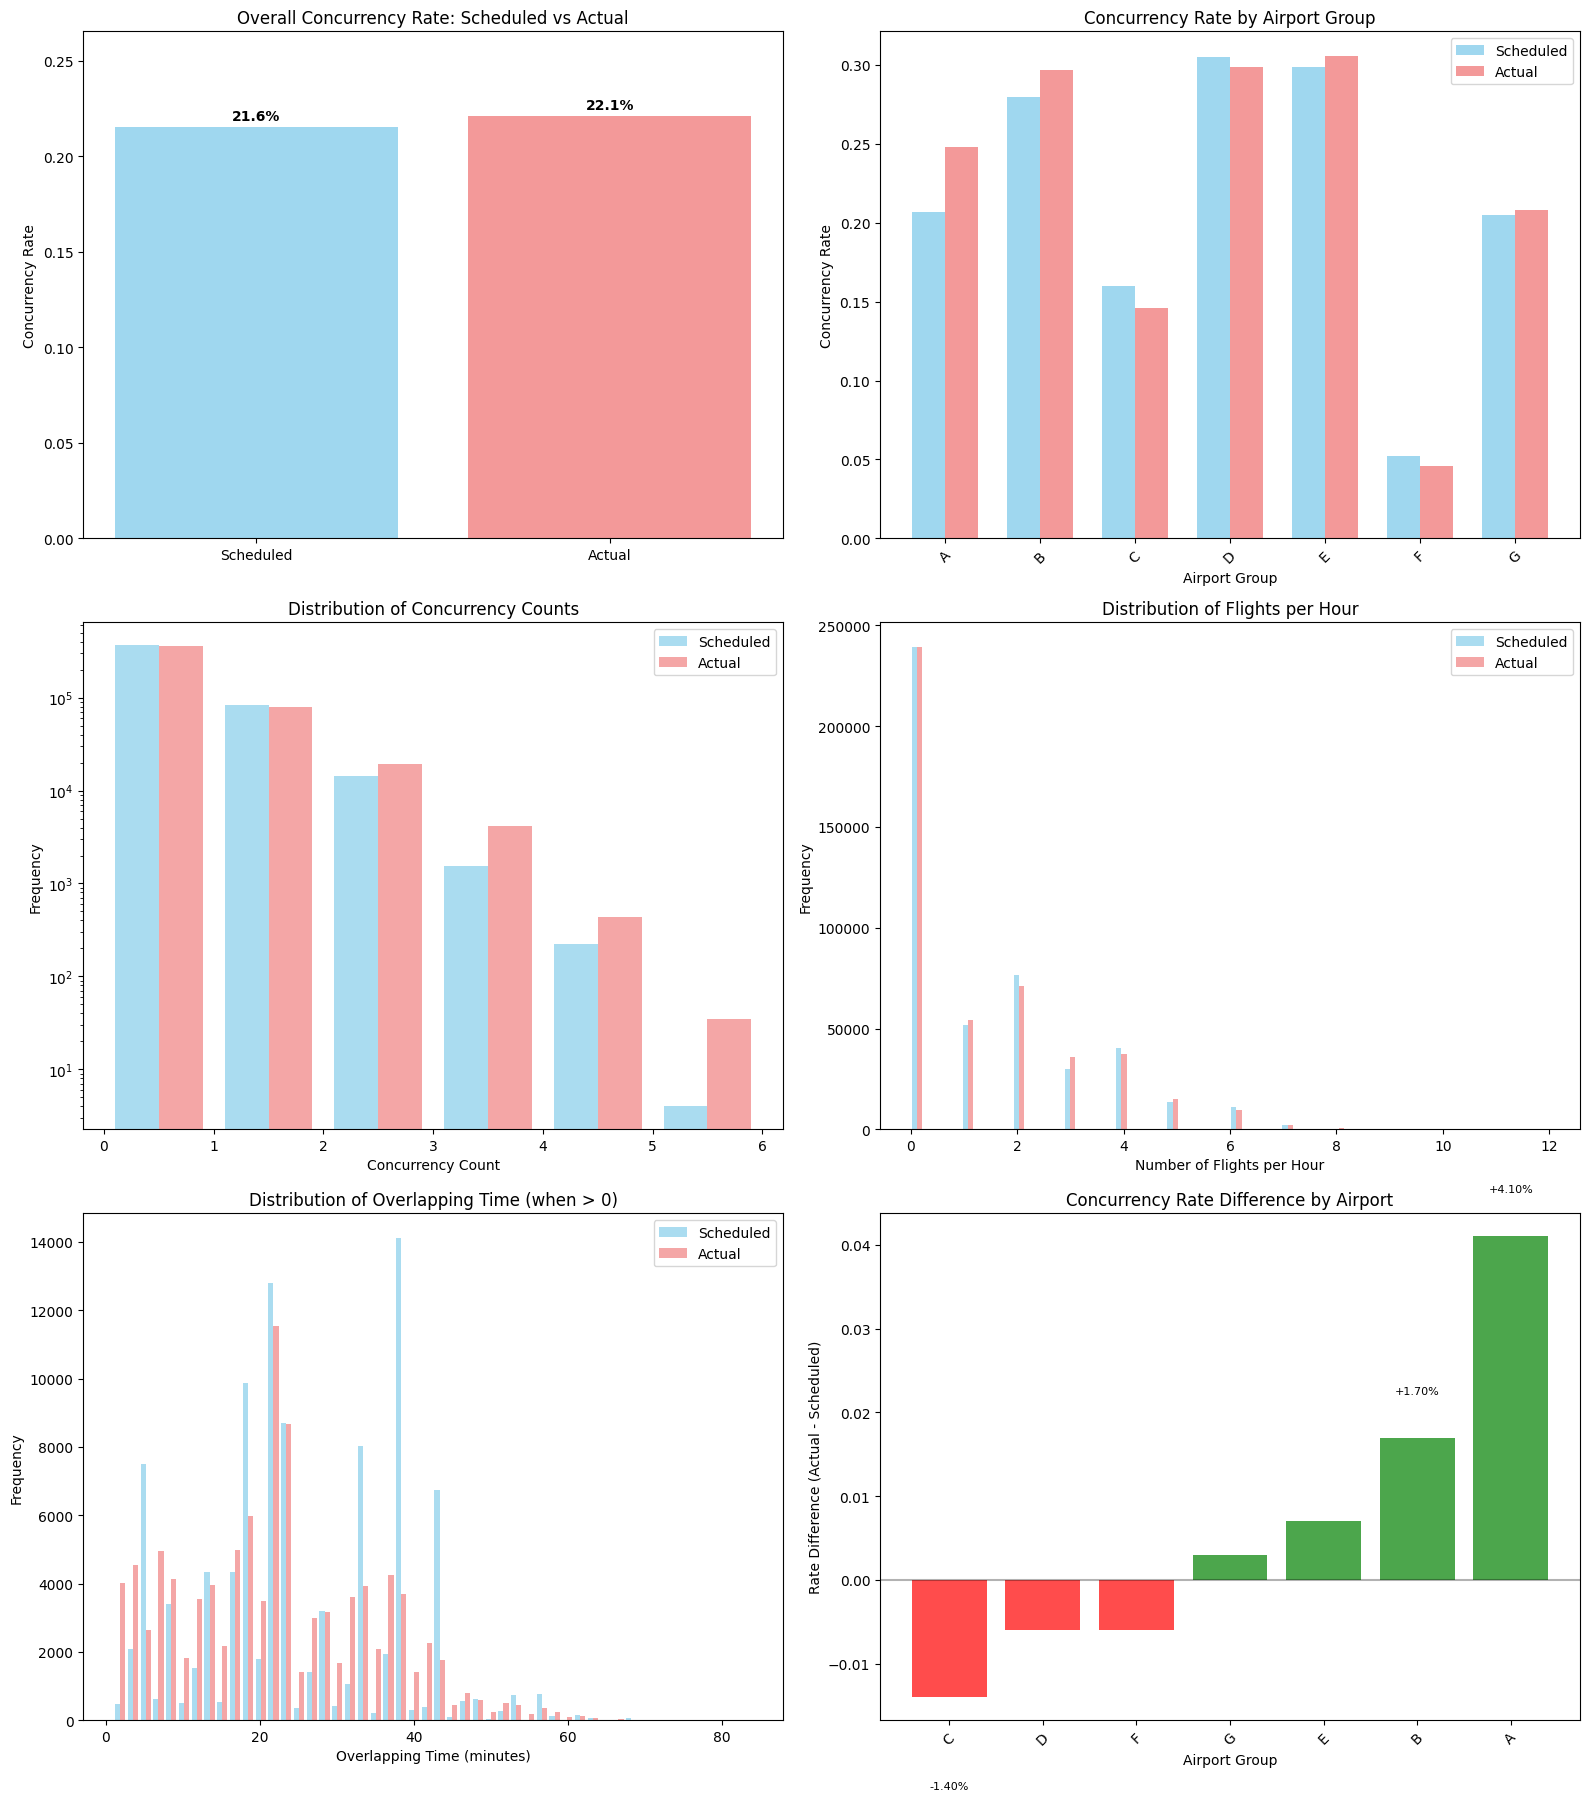

In [19]:
# Create comprehensive visualizations
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Overall concurrency rate comparison
datasets = ["Scheduled", "Actual"]
rates_oct = [scheduled_df["is_concurrency"].mean(), actual_df["is_concurrency"].mean()]
colors = ["skyblue", "lightcoral"]

bars = axes[0, 0].bar(datasets, rates_oct, color=colors, alpha=0.8)
axes[0, 0].set_ylabel("Concurrency Rate")
axes[0, 0].set_title("Overall Concurrency Rate: Scheduled vs Actual")
axes[0, 0].set_ylim(0, max(rates_oct) * 1.2)

# Add percentage labels
for bar, rate in zip(bars, rates_oct):
    axes[0, 0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(rates_oct) * 0.01,
        f"{rate:.1%}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

# 2. Airport-wise concurrency rate comparison
airport_comparison_plot = airport_comparison[["rate_sched", "rate_actual"]].fillna(0)
x_pos = range(len(airport_comparison_plot))
width = 0.35

axes[0, 1].bar(
    [x - width / 2 for x in x_pos],
    airport_comparison_plot["rate_sched"],
    width,
    label="Scheduled",
    color="skyblue",
    alpha=0.8,
)
axes[0, 1].bar(
    [x + width / 2 for x in x_pos],
    airport_comparison_plot["rate_actual"],
    width,
    label="Actual",
    color="lightcoral",
    alpha=0.8,
)

axes[0, 1].set_xlabel("Airport Group")
axes[0, 1].set_ylabel("Concurrency Rate")
axes[0, 1].set_title("Concurrency Rate by Airport Group")
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(airport_comparison_plot.index)
axes[0, 1].legend()
axes[0, 1].tick_params(axis="x", rotation=45)

# 3. Concurrency count distribution
combined_df = pd.concat([scheduled_df, actual_df])

axes[1, 0].hist(
    [scheduled_df["concurrency"], actual_df["concurrency"]],
    bins=range(0, max(combined_df["concurrency"]) + 2),
    alpha=0.7,
    label=["Scheduled", "Actual"],
    color=["skyblue", "lightcoral"],
)
axes[1, 0].set_xlabel("Concurrency Count")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].set_title("Distribution of Concurrency Counts")
axes[1, 0].legend()
axes[1, 0].set_yscale("log")  # Log scale due to potentially large differences

# 4. Number of flights distribution
axes[1, 1].hist(
    [scheduled_df["number_of_flights"], actual_df["number_of_flights"]],
    bins=50,
    alpha=0.7,
    label=["Scheduled", "Actual"],
    color=["skyblue", "lightcoral"],
)
axes[1, 1].set_xlabel("Number of Flights per Hour")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].set_title("Distribution of Flights per Hour")
axes[1, 1].legend()

# 5. Overlapping time comparison
axes[2, 0].hist(
    [
        scheduled_df[scheduled_df["overlapping_time_minutes"] > 0][
            "overlapping_time_minutes"
        ],
        actual_df[actual_df["overlapping_time_minutes"] > 0][
            "overlapping_time_minutes"
        ],
    ],
    bins=50,
    alpha=0.7,
    label=["Scheduled", "Actual"],
    color=["skyblue", "lightcoral"],
)
axes[2, 0].set_xlabel("Overlapping Time (minutes)")
axes[2, 0].set_ylabel("Frequency")
axes[2, 0].set_title("Distribution of Overlapping Time (when > 0)")
axes[2, 0].legend()

# 6. Rate difference by airport group
rate_diff_oct = airport_comparison["rate_difference"].fillna(0).sort_values()
colors_diff = ["red" if x < 0 else "green" for x in rate_diff_oct]

bars_diff = axes[2, 1].bar(
    range(len(rate_diff_oct)), rate_diff_oct, color=colors_diff, alpha=0.7
)
axes[2, 1].set_xlabel("Airport Group")
axes[2, 1].set_ylabel("Rate Difference (Actual - Scheduled)")
axes[2, 1].set_title("Concurrency Rate Difference by Airport")
axes[2, 1].set_xticks(range(len(rate_diff_oct)))
axes[2, 1].set_xticklabels(rate_diff_oct.index, rotation=45)
axes[2, 1].axhline(y=0, color="black", linestyle="-", alpha=0.3)

# Add value labels for significant differences
for i, (bar, val) in enumerate(zip(bars_diff, rate_diff_oct)):
    if abs(val) > 0.01:  # Only label significant differences
        axes[2, 1].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + (0.005 if val > 0 else -0.01),
            f"{val:+.2%}",
            ha="center",
            va="bottom" if val > 0 else "top",
            fontsize=8,
        )

plt.tight_layout()
plt.show()


⏰ TIME-BASED PATTERN ANALYSIS:

Common time periods for correlation analysis: 465,192

Common time periods for correlation analysis: 465,192


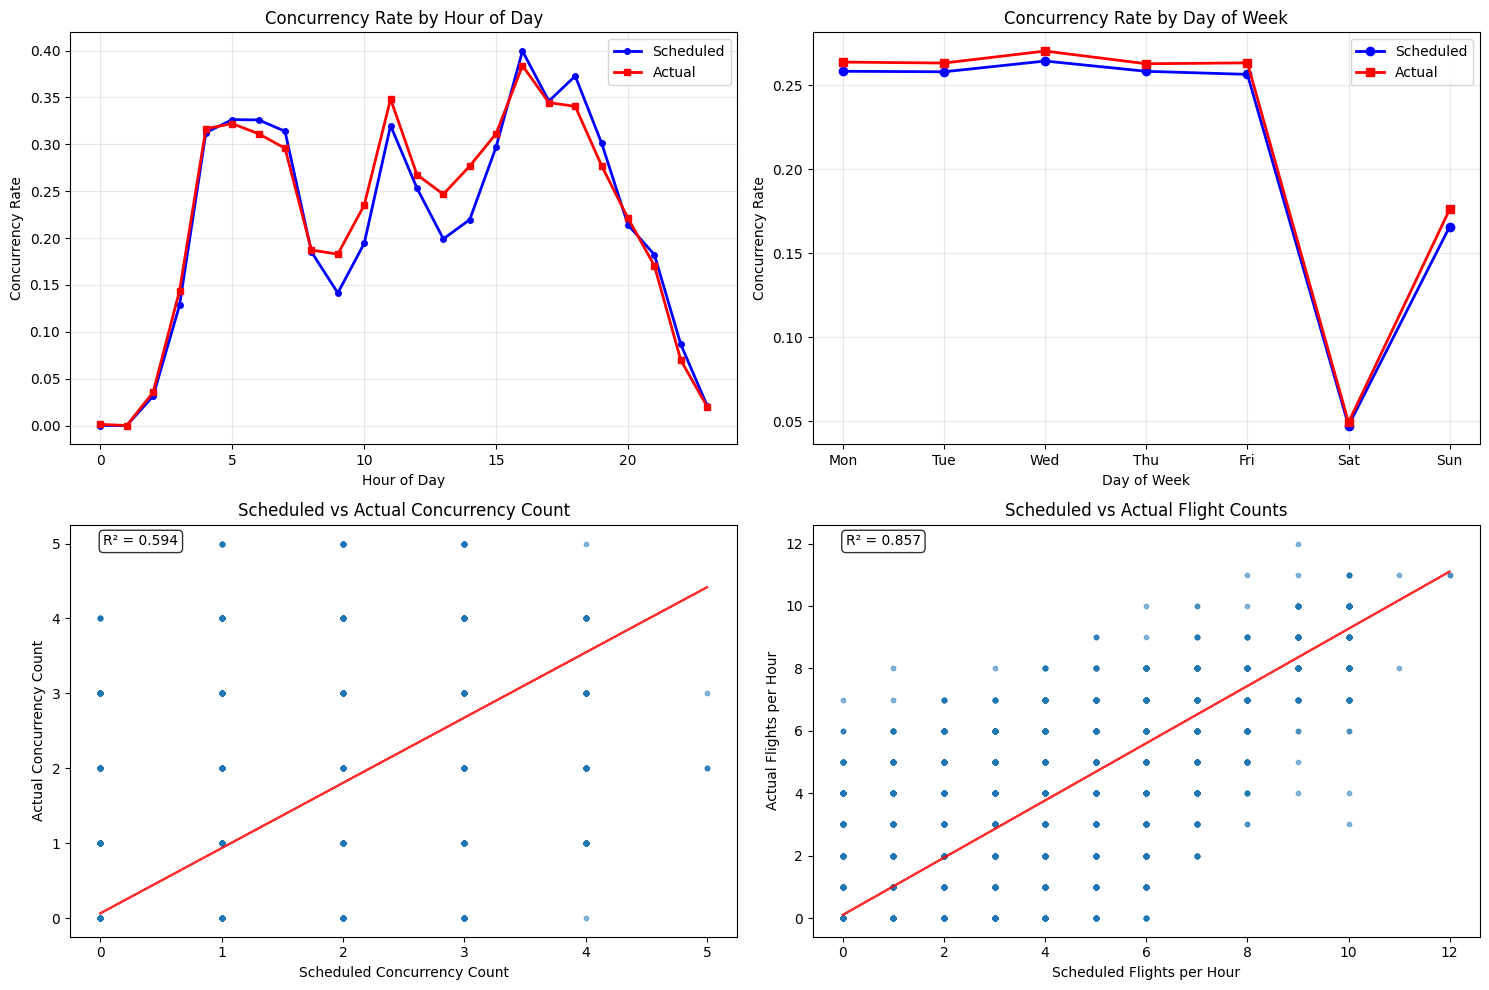


📈 CORRELATION ANALYSIS:
• Concurrency count correlation: 0.771
• Flight count correlation: 0.926
• Binary concurrency correlation: 0.796


In [20]:
# Time-based analysis
print("\n⏰ TIME-BASED PATTERN ANALYSIS:")

# Convert date columns to datetime for both datasets
scheduled_df["datetime"] = pd.to_datetime(
    scheduled_df["date"].astype(str) + " " + scheduled_df["hour"].astype(str) + ":00:00"
)
actual_df["datetime"] = pd.to_datetime(
    actual_df["date"].astype(str) + " " + actual_df["hour"].astype(str) + ":00:00"
)

# Hourly patterns
scheduled_hourly = scheduled_df.groupby("hour")["is_concurrency"].mean()
actual_hourly = actual_df.groupby("hour")["is_concurrency"].mean()

# Daily patterns (day of week)
scheduled_df["day_of_week"] = scheduled_df["datetime"].dt.dayofweek
actual_df["day_of_week"] = actual_df["datetime"].dt.dayofweek

scheduled_daily = scheduled_df.groupby("day_of_week")["is_concurrency"].mean()
actual_daily = actual_df.groupby("day_of_week")["is_concurrency"].mean()

# Plot time patterns
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Hourly pattern
axes[0, 0].plot(
    scheduled_hourly.index,
    scheduled_hourly.values,
    "b-o",
    label="Scheduled",
    linewidth=2,
    markersize=4,
)
axes[0, 0].plot(
    actual_hourly.index,
    actual_hourly.values,
    "r-s",
    label="Actual",
    linewidth=2,
    markersize=4,
)
axes[0, 0].set_xlabel("Hour of Day")
axes[0, 0].set_ylabel("Concurrency Rate")
axes[0, 0].set_title("Concurrency Rate by Hour of Day")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Daily pattern
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
axes[0, 1].plot(
    scheduled_daily.index,
    scheduled_daily.values,
    "b-o",
    label="Scheduled",
    linewidth=2,
    markersize=6,
)
axes[0, 1].plot(
    actual_daily.index,
    actual_daily.values,
    "r-s",
    label="Actual",
    linewidth=2,
    markersize=6,
)
axes[0, 1].set_xlabel("Day of Week")
axes[0, 1].set_ylabel("Concurrency Rate")
axes[0, 1].set_title("Concurrency Rate by Day of Week")
axes[0, 1].set_xticks(range(7))
axes[0, 1].set_xticklabels(day_names)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Correlation analysis between scheduled and actual
# Merge datasets on common time periods
merge_cols = ["airport_group", "date", "hour"]
comparison_df = pd.merge(
    scheduled_df[merge_cols + ["concurrency", "is_concurrency", "number_of_flights"]],
    actual_df[merge_cols + ["concurrency", "is_concurrency", "number_of_flights"]],
    on=merge_cols,
    suffixes=("_sched", "_actual"),
    how="inner",
)

print(f"\nCommon time periods for correlation analysis: {len(comparison_df):,}")

# Correlation scatter plots
axes[1, 0].scatter(
    comparison_df["concurrency_sched"],
    comparison_df["concurrency_actual"],
    alpha=0.5,
    s=10,
)
axes[1, 0].set_xlabel("Scheduled Concurrency Count")
axes[1, 0].set_ylabel("Actual Concurrency Count")
axes[1, 0].set_title("Scheduled vs Actual Concurrency Count")

# Add correlation line
from scipy import stats

if len(comparison_df) > 0:
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        comparison_df["concurrency_sched"], comparison_df["concurrency_actual"]
    )
    line = slope * comparison_df["concurrency_sched"] + intercept
    axes[1, 0].plot(comparison_df["concurrency_sched"], line, "r-", alpha=0.8)
    axes[1, 0].text(
        0.05,
        0.95,
        f"R² = {r_value**2:.3f}",
        transform=axes[1, 0].transAxes,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
    )

# Flight count correlation
axes[1, 1].scatter(
    comparison_df["number_of_flights_sched"],
    comparison_df["number_of_flights_actual"],
    alpha=0.5,
    s=10,
)
axes[1, 1].set_xlabel("Scheduled Flights per Hour")
axes[1, 1].set_ylabel("Actual Flights per Hour")
axes[1, 1].set_title("Scheduled vs Actual Flight Counts")

if len(comparison_df) > 0:
    slope2, intercept2, r_value2, p_value2, std_err2 = stats.linregress(
        comparison_df["number_of_flights_sched"],
        comparison_df["number_of_flights_actual"],
    )
    line2 = slope2 * comparison_df["number_of_flights_sched"] + intercept2
    axes[1, 1].plot(comparison_df["number_of_flights_sched"], line2, "r-", alpha=0.8)
    axes[1, 1].text(
        0.05,
        0.95,
        f"R² = {r_value2**2:.3f}",
        transform=axes[1, 1].transAxes,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
    )

plt.tight_layout()
plt.show()

# Print correlation statistics
if len(comparison_df) > 0:
    concurrency_corr = comparison_df["concurrency_sched"].corr(
        comparison_df["concurrency_actual"]
    )
    flights_corr = comparison_df["number_of_flights_sched"].corr(
        comparison_df["number_of_flights_actual"]
    )
    binary_corr = comparison_df["is_concurrency_sched"].corr(
        comparison_df["is_concurrency_actual"]
    )

    print(f"\n📈 CORRELATION ANALYSIS:")
    print(f"• Concurrency count correlation: {concurrency_corr:.3f}")
    print(f"• Flight count correlation: {flights_corr:.3f}")
    print(f"• Binary concurrency correlation: {binary_corr:.3f}")

In [21]:
# Final insights and recommendations
print("\n🎯 KEY INSIGHTS AND RECOMMENDATIONS:")
print("=" * 60)

# Calculate key metrics
if len(comparison_df) > 0:
    # Agreement analysis
    perfect_agreement = (
        comparison_df["is_concurrency_sched"] == comparison_df["is_concurrency_actual"]
    ).mean()

    # Confusion matrix style analysis
    tp = (
        (comparison_df["is_concurrency_sched"] == 1)
        & (comparison_df["is_concurrency_actual"] == 1)
    ).sum()
    fp = (
        (comparison_df["is_concurrency_sched"] == 1)
        & (comparison_df["is_concurrency_actual"] == 0)
    ).sum()
    tn = (
        (comparison_df["is_concurrency_sched"] == 0)
        & (comparison_df["is_concurrency_actual"] == 0)
    ).sum()
    fn = (
        (comparison_df["is_concurrency_sched"] == 0)
        & (comparison_df["is_concurrency_actual"] == 1)
    ).sum()

    total = tp + fp + tn + fn

    if total > 0:
        accuracy = (tp + tn) / total
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = (
            2 * (precision * recall) / (precision + recall)
            if (precision + recall) > 0
            else 0
        )

        print(f"\n📊 PREDICTION PERFORMANCE:")
        print(f"• Schedule accuracy in predicting actual concurrency: {accuracy:.1%}")
        print(
            f"• Precision (when schedule predicts concurrency, how often it's right): {precision:.1%}"
        )
        print(
            f"• Recall (of actual concurrency events, how many were predicted): {recall:.1%}"
        )
        print(f"• F1-Score: {f1:.3f}")

        print(f"\n🔍 DETAILED BREAKDOWN:")
        print(f"• True Positives (correctly predicted concurrency): {tp:,}")
        print(f"• False Positives (predicted concurrency, but none occurred): {fp:,}")
        print(f"• True Negatives (correctly predicted no concurrency): {tn:,}")
        print(f"• False Negatives (missed actual concurrency): {fn:,}")

# Business insights
print(f"\n💼 BUSINESS IMPLICATIONS:")

if "rate_difference" in locals():
    avg_rate_diff = airport_comparison["rate_difference"].mean()
    if avg_rate_diff > 0.05:
        print(
            f"• ⚠️  Actual concurrency is significantly higher than scheduled (+{avg_rate_diff:.1%} on average)"
        )
        print("• This suggests schedules are too optimistic about airport capacity")
        print(
            "• Recommendation: Add buffer time or reduce scheduled flights during peak hours"
        )
    elif avg_rate_diff < -0.05:
        print(
            f"• ✅ Actual concurrency is lower than scheduled ({avg_rate_diff:.1%} on average)"
        )
        print("• This suggests conservative scheduling with room for optimization")
        print("• Recommendation: Consider increasing capacity utilization")
    else:
        print(
            f"• ✅ Actual concurrency closely matches scheduled ({avg_rate_diff:+.1%} difference)"
        )
        print("• This indicates good schedule planning accuracy")

print(f"\n🎯 ACTIONABLE RECOMMENDATIONS:")
print("1. **Real-time Monitoring**: Use actual data to adjust schedules dynamically")
print(
    "2. **Airport-specific Strategies**: Focus on airports with largest scheduled vs actual differences"
)
print(
    "3. **Peak Hour Management**: Implement special procedures during high-concurrency hours"
)
print(
    "4. **Predictive Modeling**: Use these patterns to improve future schedule planning"
)
print(
    "5. **Resource Allocation**: Pre-position resources at airports with high actual concurrency"
)

# Create summary statistics table
summary_stats = pd.DataFrame(
    {
        "Metric": [
            "Total Hours",
            "Hours with Concurrency",
            "Concurrency Rate",
            "Avg Flights/Hour",
            "Max Concurrency",
            "Avg Overlap Time (min)",
        ],
        "Scheduled": [
            f"{len(scheduled_df):,}",
            f"{scheduled_df['is_concurrency'].sum():,}",
            f"{scheduled_df['is_concurrency'].mean():.2%}",
            f"{scheduled_df['number_of_flights'].mean():.1f}",
            f"{scheduled_df['concurrency'].max()}",
            f"{scheduled_df[scheduled_df['overlapping_time_minutes']>0]['overlapping_time_minutes'].mean():.1f}",
        ],
        "Actual": [
            f"{len(actual_df):,}",
            f"{actual_df['is_concurrency'].sum():,}",
            f"{actual_df['is_concurrency'].mean():.2%}",
            f"{actual_df['number_of_flights'].mean():.1f}",
            f"{actual_df['concurrency'].max()}",
            f"{actual_df[actual_df['overlapping_time_minutes']>0]['overlapping_time_minutes'].mean():.1f}",
        ],
    }
)

print(f"\n📋 SUMMARY COMPARISON TABLE:")
print(summary_stats.to_string(index=False))

print(f"\n✅ Analysis complete! The datasets have been thoroughly compared.")


🎯 KEY INSIGHTS AND RECOMMENDATIONS:

📊 PREDICTION PERFORMANCE:
• Schedule accuracy in predicting actual concurrency: 93.0%
• Precision (when schedule predicts concurrency, how often it's right): 85.2%
• Recall (of actual concurrency events, how many were predicted): 83.0%
• F1-Score: 0.841

🔍 DETAILED BREAKDOWN:
• True Positives (correctly predicted concurrency): 85,412
• False Positives (predicted concurrency, but none occurred): 14,847
• True Negatives (correctly predicted no concurrency): 347,424
• False Negatives (missed actual concurrency): 17,509

💼 BUSINESS IMPLICATIONS:
• ✅ Actual concurrency closely matches scheduled (+0.6% difference)
• This indicates good schedule planning accuracy

🎯 ACTIONABLE RECOMMENDATIONS:
1. **Real-time Monitoring**: Use actual data to adjust schedules dynamically
2. **Airport-specific Strategies**: Focus on airports with largest scheduled vs actual differences
3. **Peak Hour Management**: Implement special procedures during high-concurrency hours
4.

## October 2024 Baseline

In [22]:
import matplotlib.pyplot as plt
import pandas as pd

scheduled_df = pd.read_csv("../data/concurrency/scheduled_concurrency_october_24.csv")
actual_df = pd.read_csv("../data/concurrency/actual_concurrency_october_24.csv")

In [23]:
scheduled_df["date"] = pd.to_datetime(scheduled_df["date"])
actual_df["date"] = pd.to_datetime(actual_df["date"])

scheduled_df_oct = scheduled_df[
    (scheduled_df["date"].dt.month == 10) & (scheduled_df["date"].dt.year == 2024)
]
actual_df_oct = actual_df[
    (actual_df["date"].dt.month == 10) & (actual_df["date"].dt.year == 2024)
]

print(len(scheduled_df_oct), len(actual_df_oct))

5208 5208


In [24]:
# Comprehensive comparison analysis
print("🔍 OCTOBER SCHEDULED vs ACTUAL CONCURRENCY ANALYSIS")
print("=" * 60)

# Basic statistics comparison
print("\n📊 BASIC STATISTICS COMPARISON:")
print("\nScheduled Data:")
print(f"• Total hours analyzed: {len(scheduled_df_oct):,}")
print(f"• Hours with concurrency: {scheduled_df_oct['is_concurrency'].sum():,}")
print(f"• Concurrency rate: {scheduled_df_oct['is_concurrency'].mean():.2%}")
print(f"• Average flights per hour: {scheduled_df_oct['number_of_flights'].mean():.1f}")
print(f"• Max concurrency count: {scheduled_df_oct['concurrency'].max()}")

print("\nActual Data:")
print(f"• Total hours analyzed: {len(actual_df_oct):,}")
print(f"• Hours with concurrency: {actual_df_oct['is_concurrency'].sum():,}")
print(f"• Concurrency rate: {actual_df_oct['is_concurrency'].mean():.2%}")
print(f"• Average flights per hour: {actual_df_oct['number_of_flights'].mean():.1f}")
print(f"• Max concurrency count: {actual_df_oct['concurrency'].max()}")

# Calculate differences
scheduled_rate_oct = scheduled_df_oct["is_concurrency"].mean()
actual_rate_oct = actual_df_oct["is_concurrency"].mean()
rate_difference_oct = actual_rate_oct - scheduled_rate_oct

print(f"\n🎯 KEY DIFFERENCES:")
print(f"• Concurrency rate difference: {rate_difference_oct:+.2%}")
print(f"• Actual is {'higher' if rate_difference_oct > 0 else 'lower'} than scheduled")

# Airport group analysis
print(f"\n🏢 AIRPORT GROUP ANALYSIS:")
scheduled_by_airport = (
    scheduled_df_oct.groupby("airport_group")["is_concurrency"]
    .agg(["count", "sum", "mean"])
    .round(3)
)
actual_by_airport = (
    actual_df_oct.groupby("airport_group")["is_concurrency"]
    .agg(["count", "sum", "mean"])
    .round(3)
)

scheduled_by_airport.columns = [
    "total_hours_sched",
    "concurrent_hours_sched",
    "rate_sched",
]
actual_by_airport.columns = [
    "total_hours_actual",
    "concurrent_hours_actual",
    "rate_actual",
]

airport_comparison_oct = pd.merge(
    scheduled_by_airport,
    actual_by_airport,
    left_index=True,
    right_index=True,
    how="outer",
)
airport_comparison_oct["rate_difference"] = (
    airport_comparison_oct["rate_actual"] - airport_comparison_oct["rate_sched"]
)

print("Airport-wise concurrency rate comparison:")
print(airport_comparison_oct.sort_values("rate_difference", ascending=False))

🔍 OCTOBER SCHEDULED vs ACTUAL CONCURRENCY ANALYSIS

📊 BASIC STATISTICS COMPARISON:

Scheduled Data:
• Total hours analyzed: 5,208
• Hours with concurrency: 1,494
• Concurrency rate: 28.69%
• Average flights per hour: 1.7
• Max concurrency count: 4

Actual Data:
• Total hours analyzed: 5,208
• Hours with concurrency: 1,453
• Concurrency rate: 27.90%
• Average flights per hour: 1.6
• Max concurrency count: 4

🎯 KEY DIFFERENCES:
• Concurrency rate difference: -0.79%
• Actual is lower than scheduled

🏢 AIRPORT GROUP ANALYSIS:
Airport-wise concurrency rate comparison:
               total_hours_sched  concurrent_hours_sched  rate_sched  \
airport_group                                                          
A                            744                     183       0.246   
E                            744                     250       0.336   
C                            744                     173       0.233   
F                            744                      63       0.085  

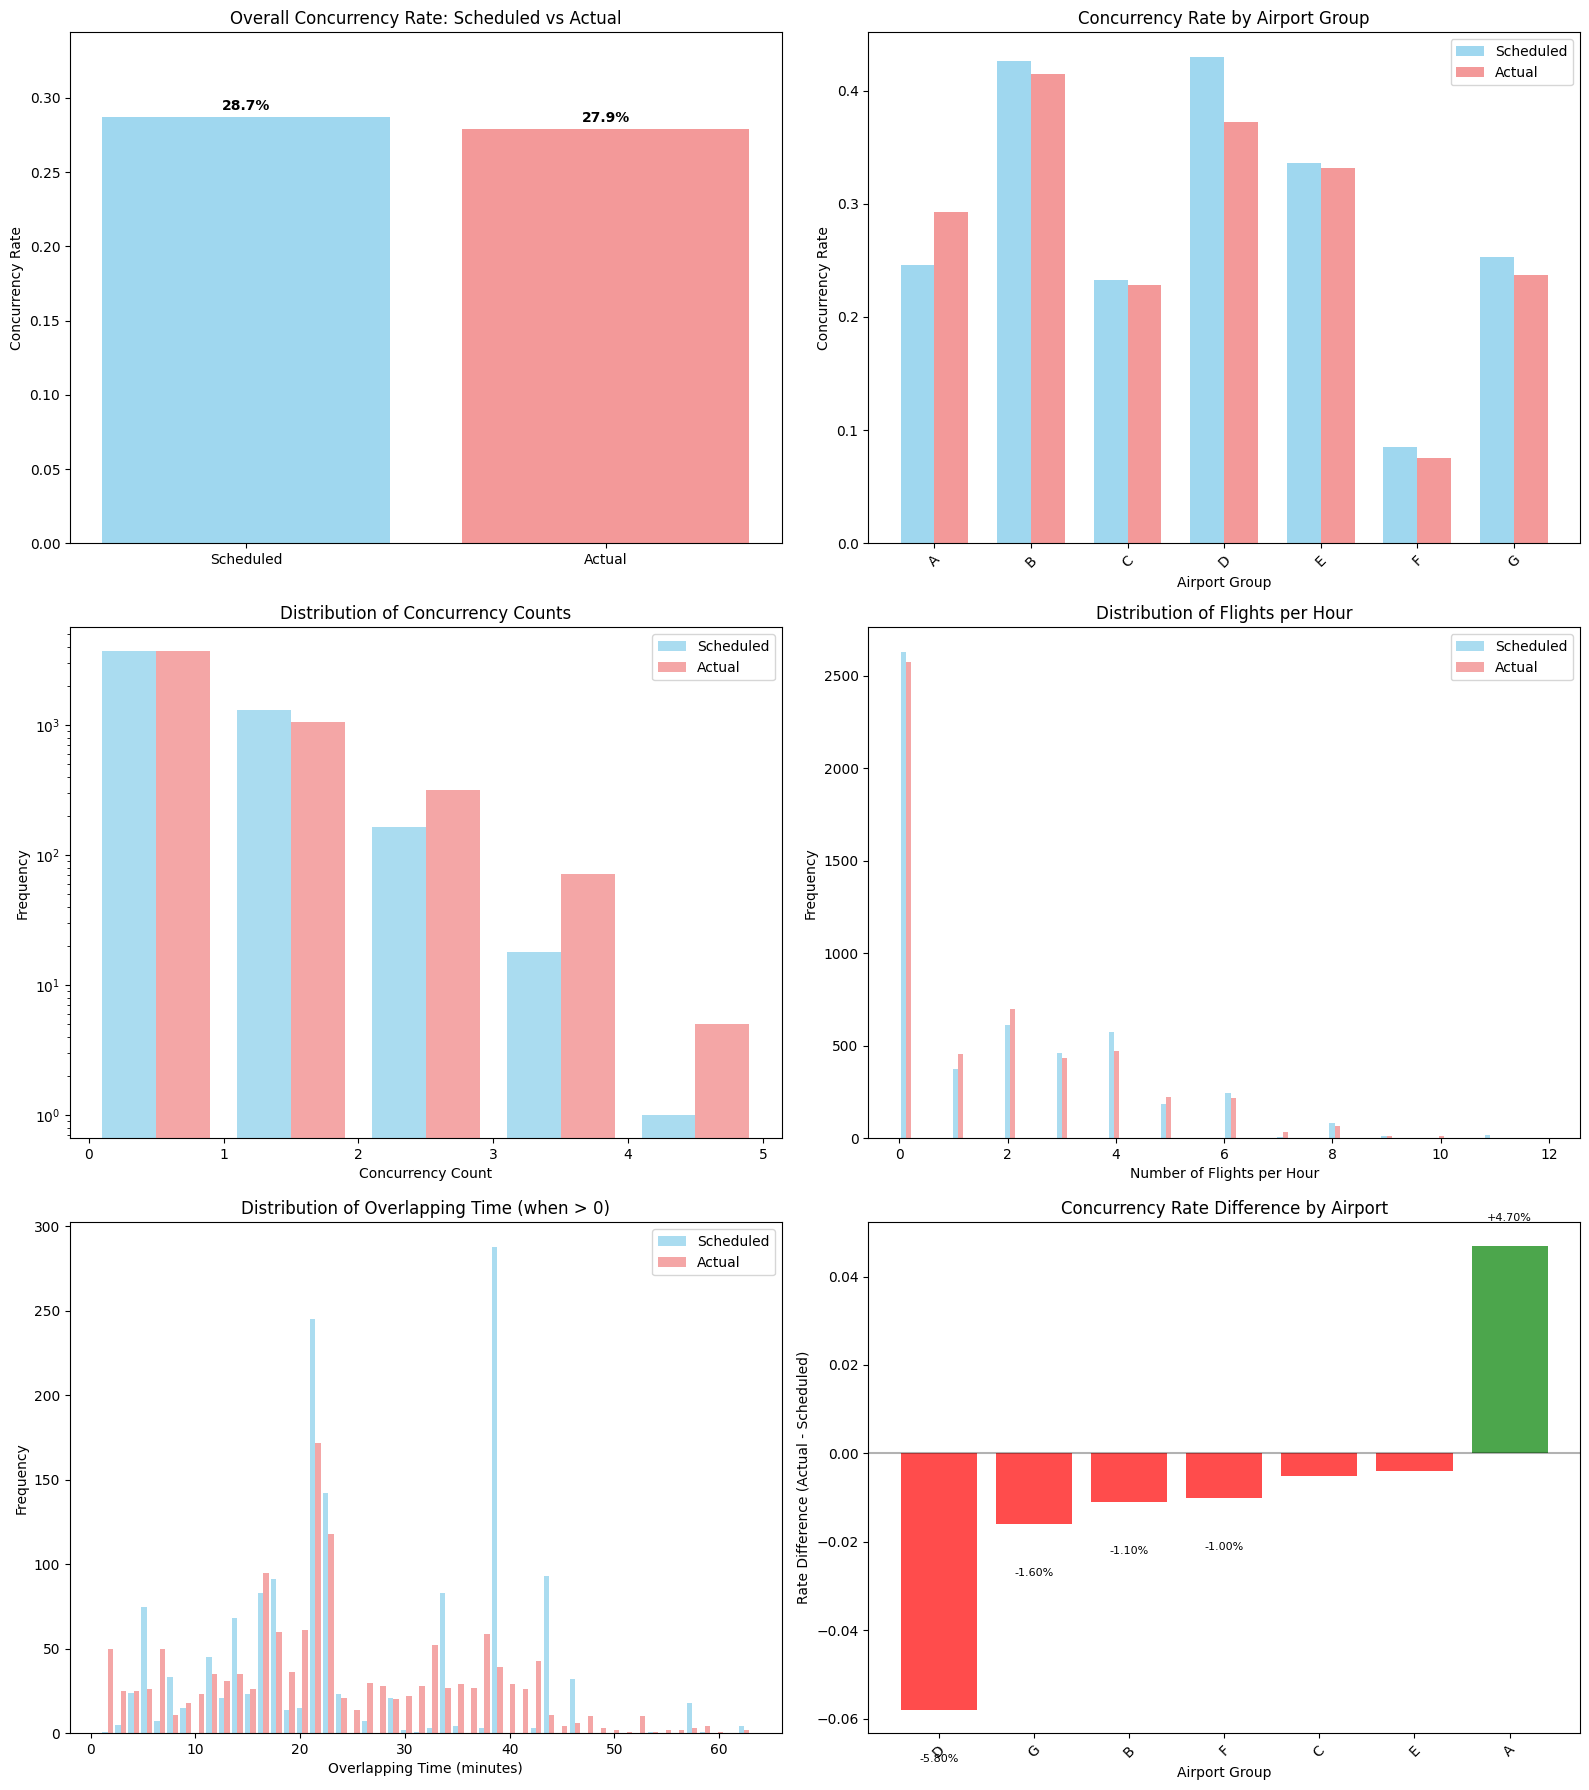

In [25]:
# Create comprehensive visualizations
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Overall concurrency rate comparison
datasets = ["Scheduled", "Actual"]
rates_oct = [
    scheduled_df_oct["is_concurrency"].mean(),
    actual_df_oct["is_concurrency"].mean(),
]
colors = ["skyblue", "lightcoral"]

bars_oct = axes[0, 0].bar(datasets, rates_oct, color=colors, alpha=0.8)
axes[0, 0].set_ylabel("Concurrency Rate")
axes[0, 0].set_title("Overall Concurrency Rate: Scheduled vs Actual")
axes[0, 0].set_ylim(0, max(rates_oct) * 1.2)

# Add percentage labels
for bar, rate in zip(bars_oct, rates_oct):
    axes[0, 0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(rates_oct) * 0.01,
        f"{rate:.1%}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

# 2. Airport-wise concurrency rate comparison
airport_comparison_plot = airport_comparison_oct[["rate_sched", "rate_actual"]].fillna(
    0
)
x_pos = range(len(airport_comparison_plot))
width = 0.35

axes[0, 1].bar(
    [x - width / 2 for x in x_pos],
    airport_comparison_plot["rate_sched"],
    width,
    label="Scheduled",
    color="skyblue",
    alpha=0.8,
)
axes[0, 1].bar(
    [x + width / 2 for x in x_pos],
    airport_comparison_plot["rate_actual"],
    width,
    label="Actual",
    color="lightcoral",
    alpha=0.8,
)

axes[0, 1].set_xlabel("Airport Group")
axes[0, 1].set_ylabel("Concurrency Rate")
axes[0, 1].set_title("Concurrency Rate by Airport Group")
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(airport_comparison_plot.index)
axes[0, 1].legend()
axes[0, 1].tick_params(axis="x", rotation=45)

# 3. Concurrency count distribution
combined_df = pd.concat([scheduled_df_oct, actual_df_oct])

axes[1, 0].hist(
    [scheduled_df_oct["concurrency"], actual_df_oct["concurrency"]],
    bins=range(0, max(combined_df["concurrency"]) + 2),
    alpha=0.7,
    label=["Scheduled", "Actual"],
    color=["skyblue", "lightcoral"],
)
axes[1, 0].set_xlabel("Concurrency Count")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].set_title("Distribution of Concurrency Counts")
axes[1, 0].legend()
axes[1, 0].set_yscale("log")  # Log scale due to potentially large differences

# 4. Number of flights distribution
axes[1, 1].hist(
    [scheduled_df_oct["number_of_flights"], actual_df_oct["number_of_flights"]],
    bins=50,
    alpha=0.7,
    label=["Scheduled", "Actual"],
    color=["skyblue", "lightcoral"],
)
axes[1, 1].set_xlabel("Number of Flights per Hour")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].set_title("Distribution of Flights per Hour")
axes[1, 1].legend()

# 5. Overlapping time comparison
axes[2, 0].hist(
    [
        scheduled_df_oct[scheduled_df_oct["overlapping_time_minutes"] > 0][
            "overlapping_time_minutes"
        ],
        actual_df_oct[actual_df_oct["overlapping_time_minutes"] > 0][
            "overlapping_time_minutes"
        ],
    ],
    bins=50,
    alpha=0.7,
    label=["Scheduled", "Actual"],
    color=["skyblue", "lightcoral"],
)
axes[2, 0].set_xlabel("Overlapping Time (minutes)")
axes[2, 0].set_ylabel("Frequency")
axes[2, 0].set_title("Distribution of Overlapping Time (when > 0)")
axes[2, 0].legend()

# 6. Rate difference by airport group
rate_diff_oct = airport_comparison_oct["rate_difference"].fillna(0).sort_values()
colors_diff = ["red" if x < 0 else "green" for x in rate_diff_oct]

bars_diff_oct = axes[2, 1].bar(
    range(len(rate_diff_oct)), rate_diff_oct, color=colors_diff, alpha=0.7
)
axes[2, 1].set_xlabel("Airport Group")
axes[2, 1].set_ylabel("Rate Difference (Actual - Scheduled)")
axes[2, 1].set_title("Concurrency Rate Difference by Airport")
axes[2, 1].set_xticks(range(len(rate_diff_oct)))
axes[2, 1].set_xticklabels(rate_diff_oct.index, rotation=45)
axes[2, 1].axhline(y=0, color="black", linestyle="-", alpha=0.3)

# Add value labels for significant differences
for i, (bar, val) in enumerate(zip(bars_diff_oct, rate_diff_oct)):
    if abs(val) > 0.01:  # Only label significant differences
        axes[2, 1].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + (0.005 if val > 0 else -0.01),
            f"{val:+.2%}",
            ha="center",
            va="bottom" if val > 0 else "top",
            fontsize=8,
        )

plt.tight_layout()
plt.show()


⏰ TIME-BASED PATTERN ANALYSIS:

Common time periods for correlation analysis: 5,208


/tmp/ipykernel_1132817/2707406685.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  actual_df_oct["datetime"] = pd.to_datetime(
/tmp/ipykernel_1132817/2707406685.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  actual_df_oct["day_of_week"] = actual_df_oct["datetime"].dt.dayofweek


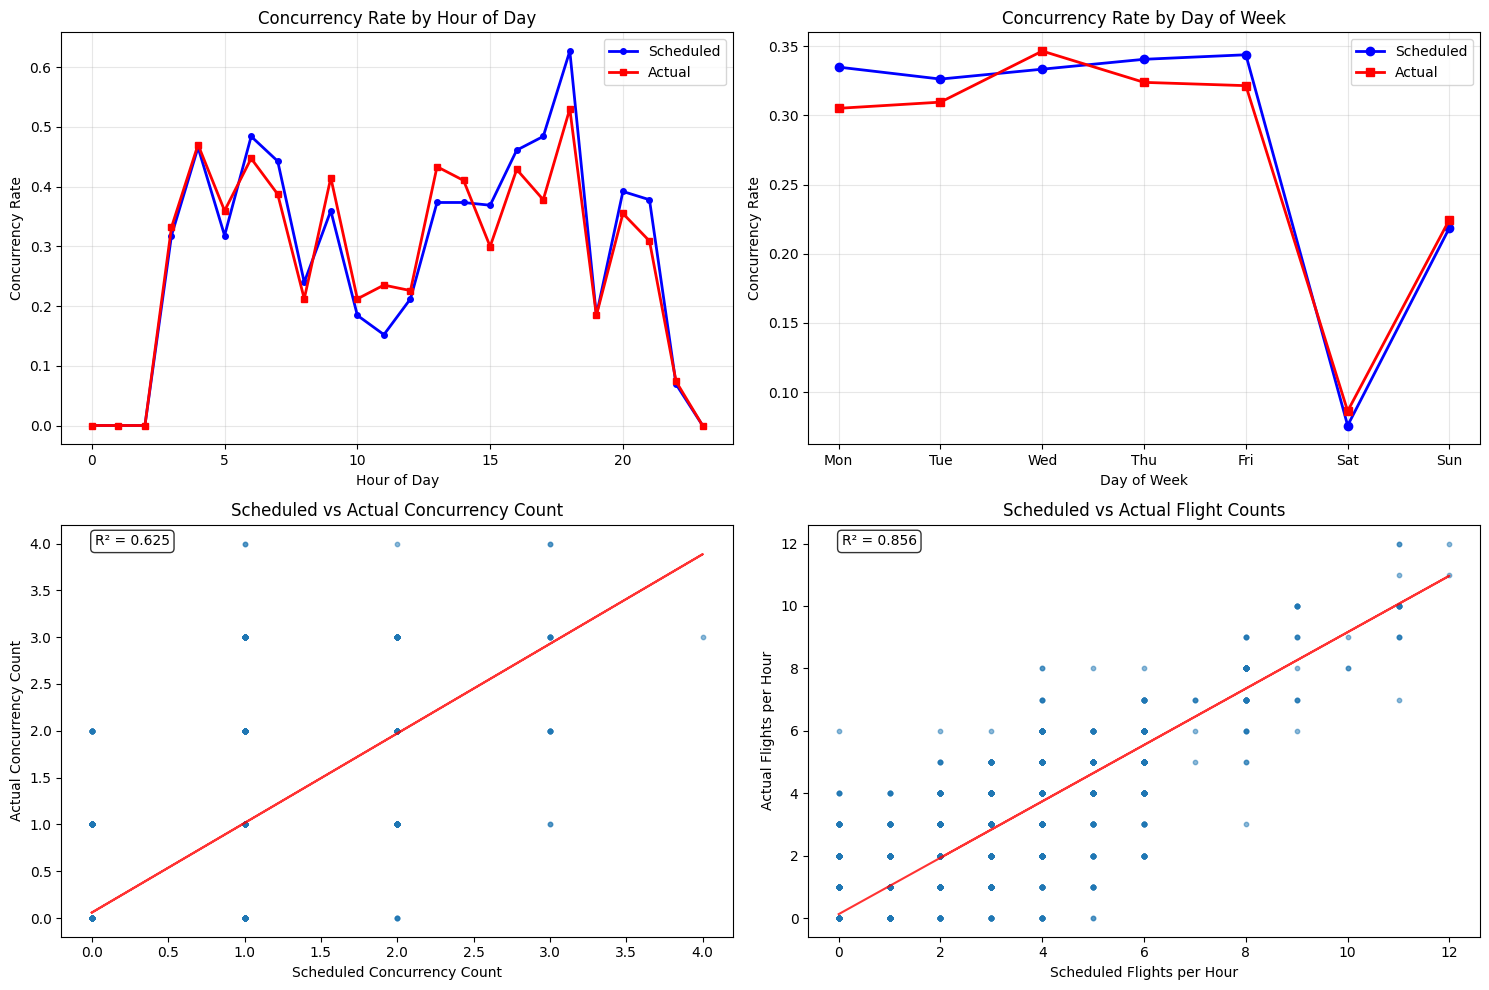


📈 CORRELATION ANALYSIS:
• Concurrency count correlation: 0.791
• Flight count correlation: 0.925
• Binary concurrency correlation: 0.821


In [26]:
# Time-based analysis
print("\n⏰ TIME-BASED PATTERN ANALYSIS:")

# Convert date columns to datetime for both datasets
scheduled_df_oct["datetime"] = pd.to_datetime(
    scheduled_df_oct["date"].astype(str)
    + " "
    + scheduled_df_oct["hour"].astype(str)
    + ":00:00"
)
actual_df_oct["datetime"] = pd.to_datetime(
    actual_df_oct["date"].astype(str)
    + " "
    + actual_df_oct["hour"].astype(str)
    + ":00:00"
)

# Hourly patterns
scheduled_hourly = scheduled_df_oct.groupby("hour")["is_concurrency"].mean()
actual_hourly = actual_df_oct.groupby("hour")["is_concurrency"].mean()

# Daily patterns (day of week)
scheduled_df_oct["day_of_week"] = scheduled_df_oct["datetime"].dt.dayofweek
actual_df_oct["day_of_week"] = actual_df_oct["datetime"].dt.dayofweek

scheduled_daily = scheduled_df_oct.groupby("day_of_week")["is_concurrency"].mean()
actual_daily = actual_df_oct.groupby("day_of_week")["is_concurrency"].mean()

# Plot time patterns
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Hourly pattern
axes[0, 0].plot(
    scheduled_hourly.index,
    scheduled_hourly.values,
    "b-o",
    label="Scheduled",
    linewidth=2,
    markersize=4,
)
axes[0, 0].plot(
    actual_hourly.index,
    actual_hourly.values,
    "r-s",
    label="Actual",
    linewidth=2,
    markersize=4,
)
axes[0, 0].set_xlabel("Hour of Day")
axes[0, 0].set_ylabel("Concurrency Rate")
axes[0, 0].set_title("Concurrency Rate by Hour of Day")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Daily pattern
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
axes[0, 1].plot(
    scheduled_daily.index,
    scheduled_daily.values,
    "b-o",
    label="Scheduled",
    linewidth=2,
    markersize=6,
)
axes[0, 1].plot(
    actual_daily.index,
    actual_daily.values,
    "r-s",
    label="Actual",
    linewidth=2,
    markersize=6,
)
axes[0, 1].set_xlabel("Day of Week")
axes[0, 1].set_ylabel("Concurrency Rate")
axes[0, 1].set_title("Concurrency Rate by Day of Week")
axes[0, 1].set_xticks(range(7))
axes[0, 1].set_xticklabels(day_names)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Correlation analysis between scheduled and actual
# Merge datasets on common time periods
merge_cols = ["airport_group", "date", "hour"]
comparison_df_oct = pd.merge(
    scheduled_df_oct[
        merge_cols + ["concurrency", "is_concurrency", "number_of_flights"]
    ],
    actual_df_oct[merge_cols + ["concurrency", "is_concurrency", "number_of_flights"]],
    on=merge_cols,
    suffixes=("_sched", "_actual"),
    how="inner",
)

print(f"\nCommon time periods for correlation analysis: {len(comparison_df_oct):,}")

# Correlation scatter plots
axes[1, 0].scatter(
    comparison_df_oct["concurrency_sched"],
    comparison_df_oct["concurrency_actual"],
    alpha=0.5,
    s=10,
)
axes[1, 0].set_xlabel("Scheduled Concurrency Count")
axes[1, 0].set_ylabel("Actual Concurrency Count")
axes[1, 0].set_title("Scheduled vs Actual Concurrency Count")

# Add correlation line
from scipy import stats

if len(comparison_df_oct) > 0:
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        comparison_df_oct["concurrency_sched"], comparison_df_oct["concurrency_actual"]
    )
    line = slope * comparison_df_oct["concurrency_sched"] + intercept
    axes[1, 0].plot(comparison_df_oct["concurrency_sched"], line, "r-", alpha=0.8)
    axes[1, 0].text(
        0.05,
        0.95,
        f"R² = {r_value**2:.3f}",
        transform=axes[1, 0].transAxes,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
    )

# Flight count correlation
axes[1, 1].scatter(
    comparison_df_oct["number_of_flights_sched"],
    comparison_df_oct["number_of_flights_actual"],
    alpha=0.5,
    s=10,
)
axes[1, 1].set_xlabel("Scheduled Flights per Hour")
axes[1, 1].set_ylabel("Actual Flights per Hour")
axes[1, 1].set_title("Scheduled vs Actual Flight Counts")

if len(comparison_df_oct) > 0:
    slope2, intercept2, r_value2, p_value2, std_err2 = stats.linregress(
        comparison_df_oct["number_of_flights_sched"],
        comparison_df_oct["number_of_flights_actual"],
    )
    line2 = slope2 * comparison_df_oct["number_of_flights_sched"] + intercept2
    axes[1, 1].plot(
        comparison_df_oct["number_of_flights_sched"], line2, "r-", alpha=0.8
    )
    axes[1, 1].text(
        0.05,
        0.95,
        f"R² = {r_value2**2:.3f}",
        transform=axes[1, 1].transAxes,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
    )

plt.tight_layout()
plt.show()

# Print correlation statistics
if len(comparison_df_oct) > 0:
    concurrency_corr = comparison_df_oct["concurrency_sched"].corr(
        comparison_df_oct["concurrency_actual"]
    )
    flights_corr = comparison_df_oct["number_of_flights_sched"].corr(
        comparison_df_oct["number_of_flights_actual"]
    )
    binary_corr = comparison_df_oct["is_concurrency_sched"].corr(
        comparison_df_oct["is_concurrency_actual"]
    )

    print(f"\n📈 CORRELATION ANALYSIS:")
    print(f"• Concurrency count correlation: {concurrency_corr:.3f}")
    print(f"• Flight count correlation: {flights_corr:.3f}")
    print(f"• Binary concurrency correlation: {binary_corr:.3f}")

In [27]:
# Final insights and recommendations
print("\n🎯 KEY INSIGHTS AND RECOMMENDATIONS:")
print("=" * 60)

# Calculate key metrics
if len(comparison_df_oct) > 0:
    # Agreement analysis
    perfect_agreement = (
        comparison_df_oct["is_concurrency_sched"]
        == comparison_df_oct["is_concurrency_actual"]
    ).mean()

    # Confusion matrix style analysis
    tp = (
        (comparison_df_oct["is_concurrency_sched"] == 1)
        & (comparison_df_oct["is_concurrency_actual"] == 1)
    ).sum()
    fp = (
        (comparison_df_oct["is_concurrency_sched"] == 1)
        & (comparison_df_oct["is_concurrency_actual"] == 0)
    ).sum()
    tn = (
        (comparison_df_oct["is_concurrency_sched"] == 0)
        & (comparison_df_oct["is_concurrency_actual"] == 0)
    ).sum()
    fn = (
        (comparison_df_oct["is_concurrency_sched"] == 0)
        & (comparison_df_oct["is_concurrency_actual"] == 1)
    ).sum()

    print(f"Confusion Matrix:")
    print(f"• True Positives: {tp}")
    print(f"• False Positives: {fp}")
    print(f"• True Negatives: {tn}")
    print(f"• False Negatives: {fn}")

    total = tp + fp + tn + fn

    if total > 0:
        accuracy = (tp + tn) / total
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = (
            2 * (precision * recall) / (precision + recall)
            if (precision + recall) > 0
            else 0
        )

        # Calculate AUC using sklearn
        from sklearn.metrics import roc_auc_score

        try:
            auc = roc_auc_score(
                comparison_df_oct["is_concurrency_actual"],
                comparison_df_oct["is_concurrency_sched"],
            )
        except Exception as e:
            # If AUC can't be calculated (e.g., only one class present)
            auc = None
            print(f"Note: AUC could not be calculated - {e}")

        print(f"\n📊 PREDICTION PERFORMANCE:")
        print(f"• Schedule accuracy in predicting actual concurrency: {accuracy:.1%}")
        print(
            f"• Precision (when schedule predicts concurrency, how often it's right): {precision:.1%}"
        )
        print(
            f"• Recall (of actual concurrency events, how many were predicted): {recall:.1%}"
        )
        print(f"• F1-Score: {f1:.3f}")
        if auc is not None:
            print(f"• AUC (Area Under ROC Curve): {auc:.4f}")

        print(f"\n🔍 DETAILED BREAKDOWN:")
        print(f"• True Positives (correctly predicted concurrency): {tp:,}")
        print(f"• False Positives (predicted concurrency, but none occurred): {fp:,}")
        print(f"• True Negatives (correctly predicted no concurrency): {tn:,}")
        print(f"• False Negatives (missed actual concurrency): {fn:,}")

# Business insights
print(f"\n💼 BUSINESS IMPLICATIONS:")

if "rate_difference" in locals():
    avg_rate_diff = airport_comparison["rate_difference"].mean()
    if avg_rate_diff > 0.05:
        print(
            f"• ⚠️  Actual concurrency is significantly higher than scheduled (+{avg_rate_diff:.1%} on average)"
        )
        print("• This suggests schedules are too optimistic about airport capacity")
        print(
            "• Recommendation: Add buffer time or reduce scheduled flights during peak hours"
        )
    elif avg_rate_diff < -0.05:
        print(
            f"• ✅ Actual concurrency is lower than scheduled ({avg_rate_diff:.1%} on average)"
        )
        print("• This suggests conservative scheduling with room for optimization")
        print("• Recommendation: Consider increasing capacity utilization")
    else:
        print(
            f"• ✅ Actual concurrency closely matches scheduled ({avg_rate_diff:+.1%} difference)"
        )
        print("• This indicates good schedule planning accuracy")

print(f"\n🎯 ACTIONABLE RECOMMENDATIONS:")
print("1. **Real-time Monitoring**: Use actual data to adjust schedules dynamically")
print(
    "2. **Airport-specific Strategies**: Focus on airports with largest scheduled vs actual differences"
)
print(
    "3. **Peak Hour Management**: Implement special procedures during high-concurrency hours"
)
print(
    "4. **Predictive Modeling**: Use these patterns to improve future schedule planning"
)
print(
    "5. **Resource Allocation**: Pre-position resources at airports with high actual concurrency"
)

# Create summary statistics table
summary_stats = pd.DataFrame(
    {
        "Metric": [
            "Total Hours",
            "Hours with Concurrency",
            "Concurrency Rate",
            "Avg Flights/Hour",
            "Max Concurrency",
            "Avg Overlap Time (min)",
        ],
        "Scheduled": [
            f"{len(scheduled_df_oct):,}",
            f"{scheduled_df_oct['is_concurrency'].sum():,}",
            f"{scheduled_df_oct['is_concurrency'].mean():.2%}",
            f"{scheduled_df_oct['number_of_flights'].mean():.1f}",
            f"{scheduled_df_oct['concurrency'].max()}",
            f"{scheduled_df_oct[scheduled_df_oct['overlapping_time_minutes']>0]['overlapping_time_minutes'].mean():.1f}",
        ],
        "Actual": [
            f"{len(actual_df_oct):,}",
            f"{actual_df_oct['is_concurrency'].sum():,}",
            f"{actual_df_oct['is_concurrency'].mean():.2%}",
            f"{actual_df_oct['number_of_flights'].mean():.1f}",
            f"{actual_df_oct['concurrency'].max()}",
            f"{actual_df_oct[actual_df_oct['overlapping_time_minutes']>0]['overlapping_time_minutes'].mean():.1f}",
        ],
    }
)

print(f"\n📋 SUMMARY COMPARISON TABLE:")
print(summary_stats.to_string(index=False))

print(f"\n✅ Analysis complete! The datasets have been thoroughly compared.")


🎯 KEY INSIGHTS AND RECOMMENDATIONS:
Confusion Matrix:
• True Positives: 1284
• False Positives: 210
• True Negatives: 3545
• False Negatives: 169

📊 PREDICTION PERFORMANCE:
• Schedule accuracy in predicting actual concurrency: 92.7%
• Precision (when schedule predicts concurrency, how often it's right): 85.9%
• Recall (of actual concurrency events, how many were predicted): 88.4%
• F1-Score: 0.871
• AUC (Area Under ROC Curve): 0.9139

🔍 DETAILED BREAKDOWN:
• True Positives (correctly predicted concurrency): 1,284
• False Positives (predicted concurrency, but none occurred): 210
• True Negatives (correctly predicted no concurrency): 3,545
• False Negatives (missed actual concurrency): 169

💼 BUSINESS IMPLICATIONS:
• ✅ Actual concurrency closely matches scheduled (+0.6% difference)
• This indicates good schedule planning accuracy

🎯 ACTIONABLE RECOMMENDATIONS:
1. **Real-time Monitoring**: Use actual data to adjust schedules dynamically
2. **Airport-specific Strategies**: Focus on airpor

## Three-Way Comparison: Schedule vs Predicted vs Actual October 2024

In [28]:
# Generate predicted concurrency data from df_predicted_october_24
print("🔄 Generating predicted concurrency data...")

# Apply the same concurrency processing to the predicted dataset
predicted_concurrency_oct = compute_scheduled_concurrency_optimized(
    df_predicted_october_24, include_features=True
)

# Convert to same format as scheduled and actual datasets
predicted_df_oct = predicted_concurrency_oct.copy()
predicted_df_oct["date"] = pd.to_datetime(predicted_df_oct["date"])

# Add binary concurrency target
predicted_df_oct = create_concurrency_binary_target(predicted_df_oct)

# Filter for October 2024
predicted_df_oct = predicted_df_oct[
    (predicted_df_oct["date"].dt.month == 10)
    & (predicted_df_oct["date"].dt.year == 2024)
]

print(f"📊 Dataset sizes:")
print(f"• Scheduled: {len(scheduled_df_oct):,} hours")
print(f"• Predicted: {len(predicted_df_oct):,} hours")
print(f"• Actual: {len(actual_df_oct):,} hours")

🔄 Generating predicted concurrency data...
Start time: 2024-10-01 00:00:00, End time: 2024-10-31 23:00:00
Processing airport group: A
Processing airport group: B
Processing airport group: C
Processing airport group: D
Processing airport group: E
Processing airport group: F
Processing airport group: F
Processing airport group: G
📊 Dataset sizes:
• Scheduled: 5,208 hours
• Predicted: 5,208 hours
• Actual: 5,208 hours
Processing airport group: G
📊 Dataset sizes:
• Scheduled: 5,208 hours
• Predicted: 5,208 hours
• Actual: 5,208 hours


/tmp/ipykernel_1132817/3624801019.py:64: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  time_index = pd.date_range(start=start_time, end=end_time, freq="H")


In [29]:
# Comprehensive three-way comparison analysis
print("🔍 THREE-WAY CONCURRENCY ANALYSIS: SCHEDULE vs PREDICTED vs ACTUAL")
print("=" * 80)

# Basic statistics comparison
datasets_3way = ["Scheduled", "Predicted", "Actual"]
dataframes_3way = [scheduled_df_oct, predicted_df_oct, actual_df_oct]

print("\n📊 BASIC STATISTICS COMPARISON:")
for name, df in zip(datasets_3way, dataframes_3way):
    print(f"\n{name} Data:")
    print(f"• Total hours analyzed: {len(df):,}")
    print(f"• Hours with concurrency: {df['is_concurrency'].sum():,}")
    print(f"• Concurrency rate: {df['is_concurrency'].mean():.2%}")
    print(f"• Average flights per hour: {df['number_of_flights'].mean():.1f}")
    print(f"• Max concurrency count: {df['concurrency'].max()}")

# Calculate relative improvements
scheduled_rate = scheduled_df_oct["is_concurrency"].mean()
predicted_rate = predicted_df_oct["is_concurrency"].mean()
actual_rate = actual_df_oct["is_concurrency"].mean()

print(f"\n🎯 PREDICTION PERFORMANCE:")
print(f"• Scheduled rate: {scheduled_rate:.2%}")
print(f"• Predicted rate: {predicted_rate:.2%}")
print(f"• Actual rate: {actual_rate:.2%}")
print(f"• Predicted vs Scheduled difference: {predicted_rate - scheduled_rate:+.2%}")
print(f"• Predicted vs Actual difference: {predicted_rate - actual_rate:+.2%}")
print(f"• Scheduled vs Actual difference: {scheduled_rate - actual_rate:+.2%}")

# Improvement analysis
scheduled_error = abs(scheduled_rate - actual_rate)
predicted_error = abs(predicted_rate - actual_rate)
improvement = ((scheduled_error - predicted_error) / scheduled_error) * 100

print(f"• Prediction improvement over schedule: {improvement:+.1f}%")
if improvement > 0:
    print("✅ Predictions are closer to actual than schedule!")
else:
    print("⚠️ Schedule was actually closer to actual than predictions.")

🔍 THREE-WAY CONCURRENCY ANALYSIS: SCHEDULE vs PREDICTED vs ACTUAL

📊 BASIC STATISTICS COMPARISON:

Scheduled Data:
• Total hours analyzed: 5,208
• Hours with concurrency: 1,494
• Concurrency rate: 28.69%
• Average flights per hour: 1.7
• Max concurrency count: 4

Predicted Data:
• Total hours analyzed: 5,208
• Hours with concurrency: 1,574
• Concurrency rate: 30.22%
• Average flights per hour: 1.6
• Max concurrency count: 4

Actual Data:
• Total hours analyzed: 5,208
• Hours with concurrency: 1,453
• Concurrency rate: 27.90%
• Average flights per hour: 1.6
• Max concurrency count: 4

🎯 PREDICTION PERFORMANCE:
• Scheduled rate: 28.69%
• Predicted rate: 30.22%
• Actual rate: 27.90%
• Predicted vs Scheduled difference: +1.54%
• Predicted vs Actual difference: +2.32%
• Scheduled vs Actual difference: +0.79%
• Prediction improvement over schedule: -195.1%
⚠️ Schedule was actually closer to actual than predictions.


In [30]:
# Airport group analysis for all three datasets
print(f"\n🏢 AIRPORT GROUP ANALYSIS (Three-way):")

airport_stats_3way = []

for name, df in zip(datasets_3way, dataframes_3way):
    stats = (
        df.groupby("airport_group")["is_concurrency"]
        .agg(["count", "sum", "mean"])
        .round(3)
    )
    stats.columns = [
        f"total_hours_{name.lower()}",
        f"concurrent_hours_{name.lower()}",
        f"rate_{name.lower()}",
    ]
    airport_stats_3way.append(stats)

# Merge all airport statistics
airport_comparison_3way = airport_stats_3way[0]
for stats in airport_stats_3way[1:]:
    airport_comparison_3way = pd.merge(
        airport_comparison_3way, stats, left_index=True, right_index=True, how="outer"
    )

# Calculate differences and improvements
airport_comparison_3way["scheduled_vs_actual_diff"] = (
    airport_comparison_3way["rate_actual"] - airport_comparison_3way["rate_scheduled"]
)
airport_comparison_3way["predicted_vs_actual_diff"] = (
    airport_comparison_3way["rate_actual"] - airport_comparison_3way["rate_predicted"]
)
airport_comparison_3way["predicted_vs_scheduled_diff"] = (
    airport_comparison_3way["rate_predicted"]
    - airport_comparison_3way["rate_scheduled"]
)

# Calculate improvement metric (how much closer predictions are to actual vs schedule)
airport_comparison_3way["prediction_improvement"] = (
    (
        abs(airport_comparison_3way["scheduled_vs_actual_diff"])
        - abs(airport_comparison_3way["predicted_vs_actual_diff"])
    )
    / abs(airport_comparison_3way["scheduled_vs_actual_diff"])
    * 100
)

airport_comparison_3way = airport_comparison_3way.fillna(0)

print("Three-way airport comparison (sorted by prediction improvement):")
display_cols = [
    "rate_scheduled",
    "rate_predicted",
    "rate_actual",
    "predicted_vs_actual_diff",
    "prediction_improvement",
]
print(
    airport_comparison_3way[display_cols].sort_values(
        "prediction_improvement", ascending=False
    )
)


🏢 AIRPORT GROUP ANALYSIS (Three-way):
Three-way airport comparison (sorted by prediction improvement):
               rate_scheduled  rate_predicted  rate_actual  \
airport_group                                                
A                       0.246           0.301        0.293   
F                       0.085           0.085        0.075   
D                       0.430           0.430        0.372   
G                       0.253           0.254        0.237   
B                       0.426           0.437        0.415   
E                       0.336           0.353        0.332   
C                       0.233           0.255        0.228   

               predicted_vs_actual_diff  prediction_improvement  
airport_group                                                    
A                                -0.008               82.978723  
F                                -0.010                0.000000  
D                                -0.058                0.000000  
G      

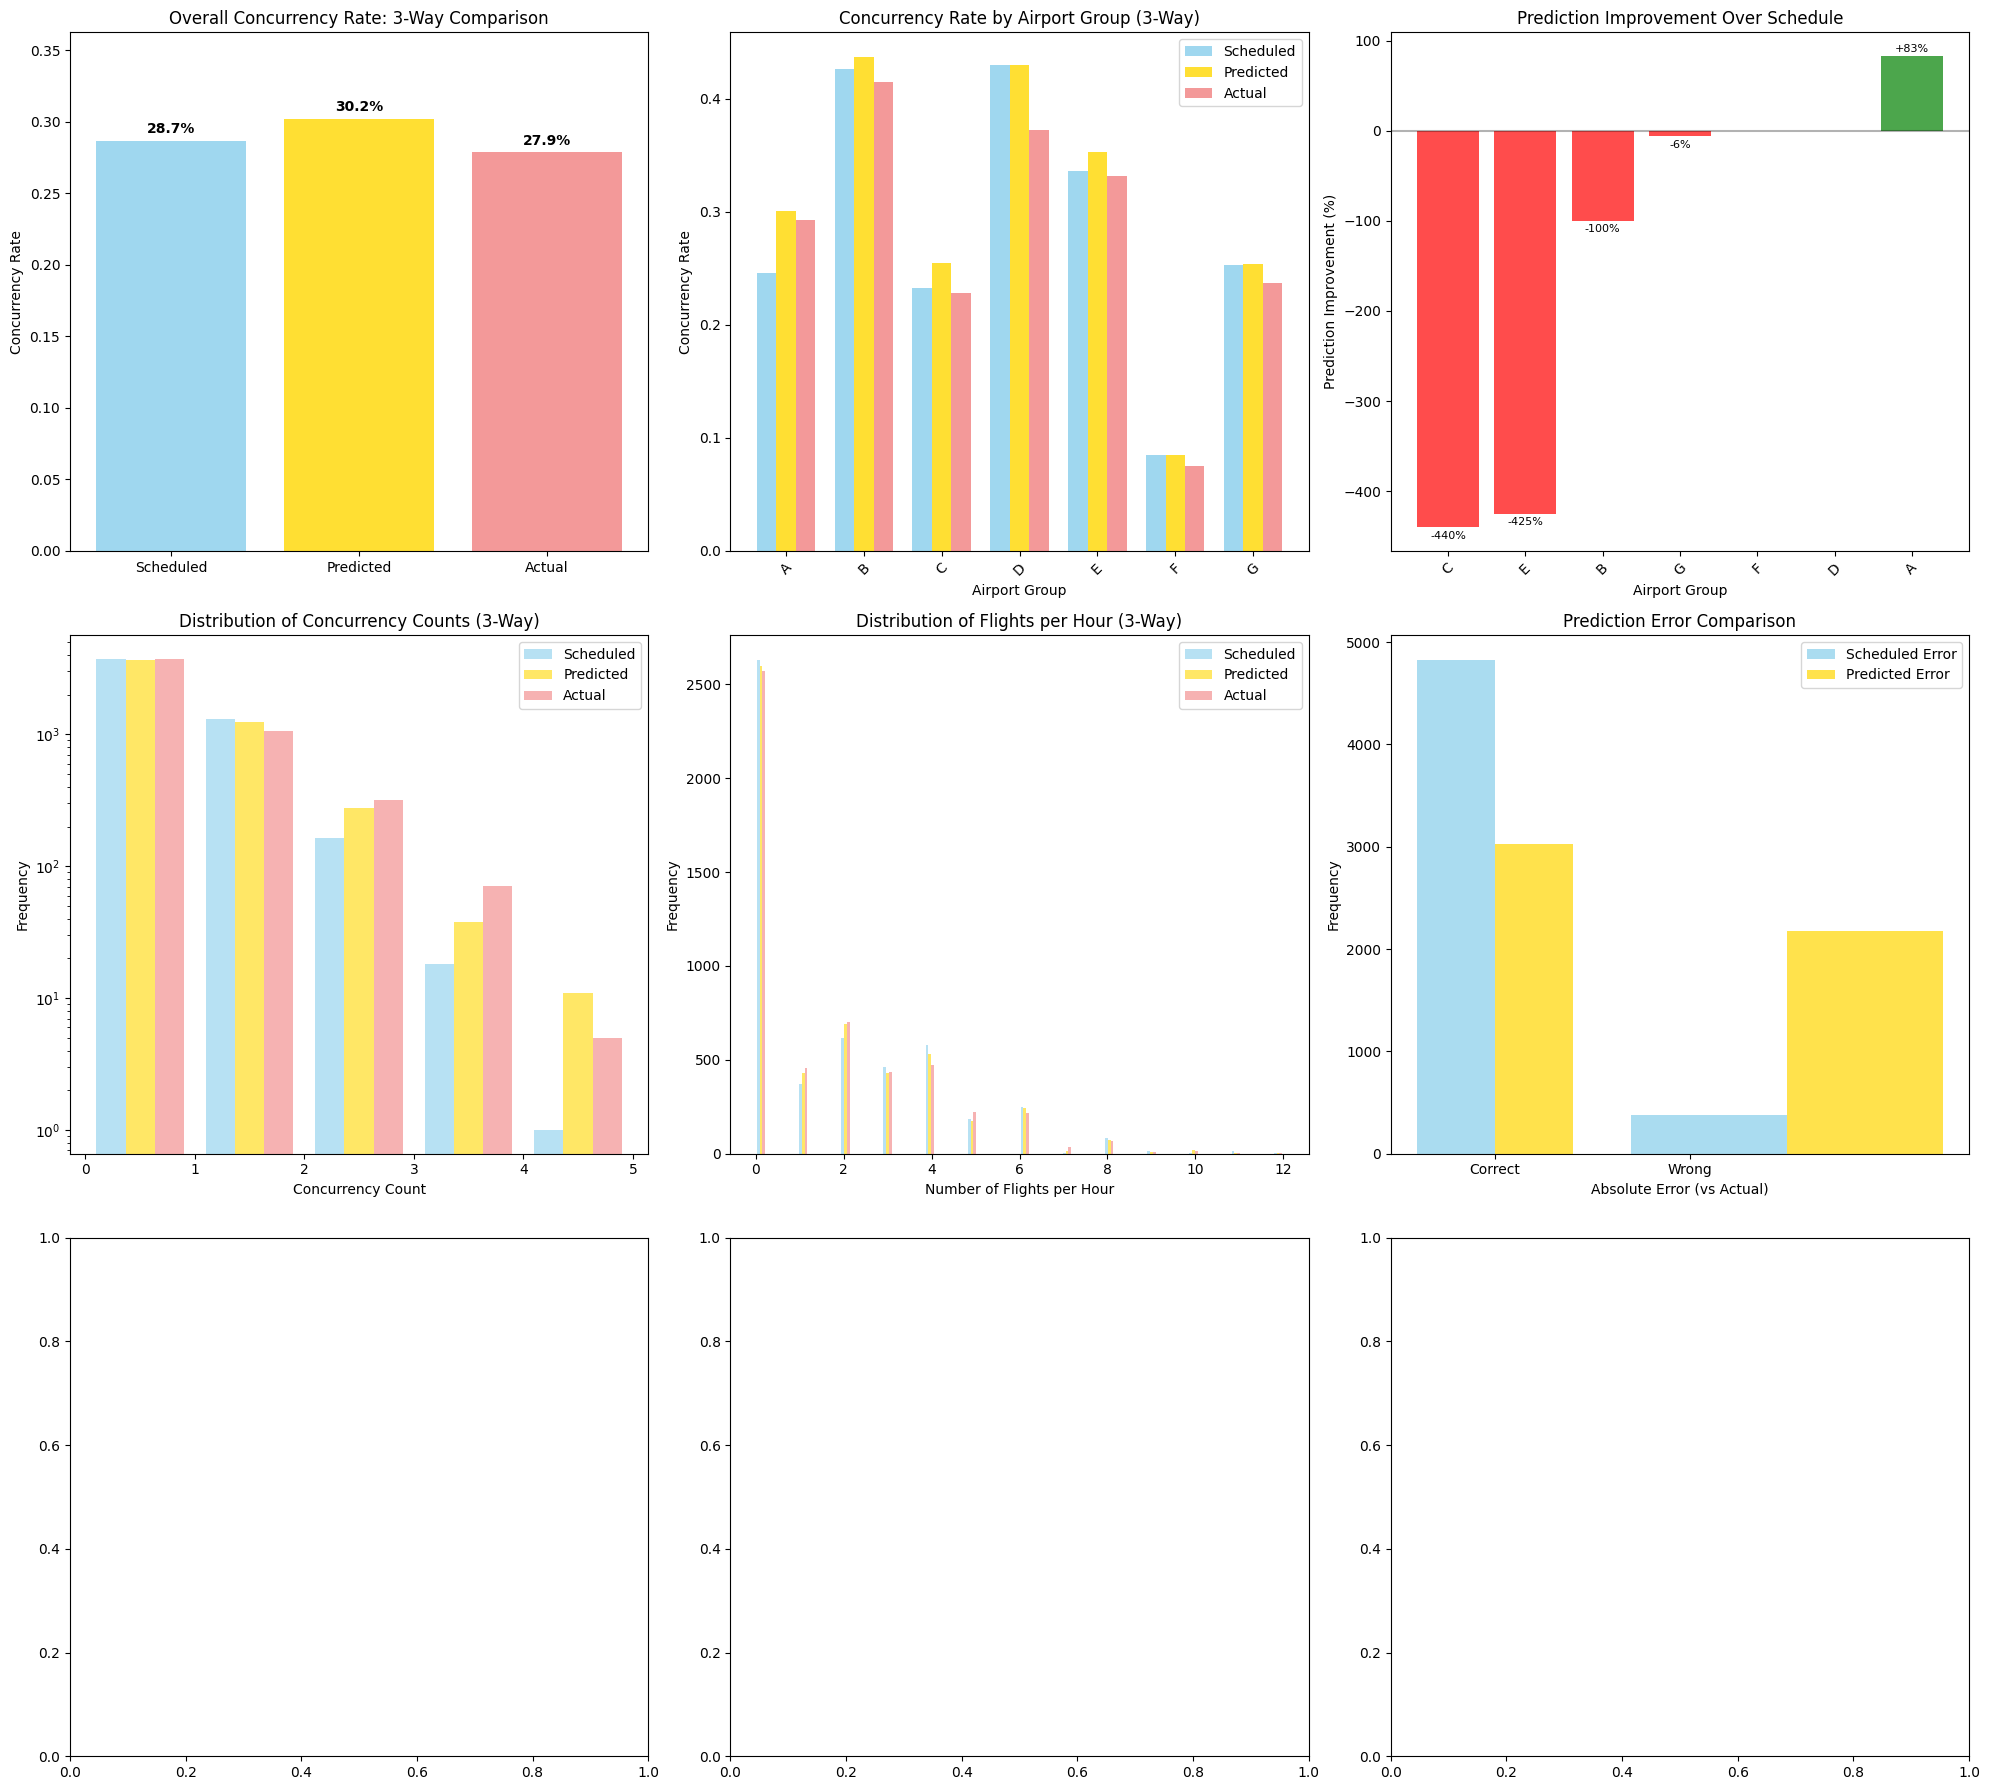

In [31]:
# Create comprehensive three-way visualizations
fig, axes = plt.subplots(3, 3, figsize=(20, 18))

# 1. Overall concurrency rate comparison (three-way)
rates_3way = [
    scheduled_df_oct["is_concurrency"].mean(),
    predicted_df_oct["is_concurrency"].mean(),
    actual_df_oct["is_concurrency"].mean(),
]
colors_3way = ["skyblue", "gold", "lightcoral"]

bars_3way = axes[0, 0].bar(datasets_3way, rates_3way, color=colors_3way, alpha=0.8)
axes[0, 0].set_ylabel("Concurrency Rate")
axes[0, 0].set_title("Overall Concurrency Rate: 3-Way Comparison")
axes[0, 0].set_ylim(0, max(rates_3way) * 1.2)

# Add percentage labels
for bar, rate in zip(bars_3way, rates_3way):
    axes[0, 0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(rates_3way) * 0.01,
        f"{rate:.1%}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

# 2. Airport-wise concurrency rate comparison (three-way)
airport_rates_3way = airport_comparison_3way[
    ["rate_scheduled", "rate_predicted", "rate_actual"]
].fillna(0)
x_pos_3way = range(len(airport_rates_3way))
width_3way = 0.25

axes[0, 1].bar(
    [x - width_3way for x in x_pos_3way],
    airport_rates_3way["rate_scheduled"],
    width_3way,
    label="Scheduled",
    color="skyblue",
    alpha=0.8,
)
axes[0, 1].bar(
    x_pos_3way,
    airport_rates_3way["rate_predicted"],
    width_3way,
    label="Predicted",
    color="gold",
    alpha=0.8,
)
axes[0, 1].bar(
    [x + width_3way for x in x_pos_3way],
    airport_rates_3way["rate_actual"],
    width_3way,
    label="Actual",
    color="lightcoral",
    alpha=0.8,
)

axes[0, 1].set_xlabel("Airport Group")
axes[0, 1].set_ylabel("Concurrency Rate")
axes[0, 1].set_title("Concurrency Rate by Airport Group (3-Way)")
axes[0, 1].set_xticks(x_pos_3way)
axes[0, 1].set_xticklabels(airport_rates_3way.index, rotation=45)
axes[0, 1].legend()

# 3. Prediction improvement by airport
improvement_data = (
    airport_comparison_3way["prediction_improvement"].fillna(0).sort_values()
)
colors_improvement = ["red" if x < 0 else "green" for x in improvement_data]

bars_improvement = axes[0, 2].bar(
    range(len(improvement_data)), improvement_data, color=colors_improvement, alpha=0.7
)
axes[0, 2].set_xlabel("Airport Group")
axes[0, 2].set_ylabel("Prediction Improvement (%)")
axes[0, 2].set_title("Prediction Improvement Over Schedule")
axes[0, 2].set_xticks(range(len(improvement_data)))
axes[0, 2].set_xticklabels(improvement_data.index, rotation=45)
axes[0, 2].axhline(y=0, color="black", linestyle="-", alpha=0.3)

# Add value labels for significant improvements
for i, (bar, val) in enumerate(zip(bars_improvement, improvement_data)):
    if abs(val) > 5:  # Only label significant improvements
        axes[0, 2].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + (2 if val > 0 else -4),
            f"{val:+.0f}%",
            ha="center",
            va="bottom" if val > 0 else "top",
            fontsize=8,
        )

# 4. Concurrency count distribution (three-way)
combined_3way = pd.concat([scheduled_df_oct, predicted_df_oct, actual_df_oct])
max_concurrency = combined_3way["concurrency"].max()

axes[1, 0].hist(
    [
        scheduled_df_oct["concurrency"],
        predicted_df_oct["concurrency"],
        actual_df_oct["concurrency"],
    ],
    bins=range(0, max_concurrency + 2),
    alpha=0.6,
    label=datasets_3way,
    color=colors_3way,
)
axes[1, 0].set_xlabel("Concurrency Count")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].set_title("Distribution of Concurrency Counts (3-Way)")
axes[1, 0].legend()
axes[1, 0].set_yscale("log")

# 5. Number of flights distribution (three-way)
axes[1, 1].hist(
    [
        scheduled_df_oct["number_of_flights"],
        predicted_df_oct["number_of_flights"],
        actual_df_oct["number_of_flights"],
    ],
    bins=50,
    alpha=0.6,
    label=datasets_3way,
    color=colors_3way,
)
axes[1, 1].set_xlabel("Number of Flights per Hour")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].set_title("Distribution of Flights per Hour (3-Way)")
axes[1, 1].legend()

# 6. Error comparison: Predicted vs Scheduled (against Actual)
scheduled_errors = abs(
    scheduled_df_oct["is_concurrency"] - actual_df_oct["is_concurrency"]
)
predicted_errors = abs(
    predicted_df_oct["is_concurrency"] - actual_df_oct["is_concurrency"]
)

axes[1, 2].hist(
    [scheduled_errors, predicted_errors],
    bins=[0, 0.5, 1.5],
    alpha=0.7,
    label=["Scheduled Error", "Predicted Error"],
    color=["skyblue", "gold"],
)
axes[1, 2].set_xlabel("Absolute Error (vs Actual)")
axes[1, 2].set_ylabel("Frequency")
axes[1, 2].set_title("Prediction Error Comparison")
axes[1, 2].legend()
axes[1, 2].set_xticks([0.25, 0.75])
axes[1, 2].set_xticklabels(["Correct", "Wrong"])

plt.tight_layout()
plt.show()


⏰ TIME-BASED PATTERN ANALYSIS (Three-Way):

📊 CORRELATION ANALYSIS:
• Scheduled vs Actual correlation: 0.821
• Predicted vs Actual correlation: -0.013
• Scheduled vs Predicted correlation: -0.026

🎯 PATTERN ACCURACY:
• Hourly pattern - Predicted error: 0.033
• Hourly pattern - Scheduled error: 0.036
• Daily pattern - Predicted error: 0.024
• Daily pattern - Scheduled error: 0.016


/tmp/ipykernel_1132817/2837132062.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  actual_df_oct["day_of_week"] = pd.to_datetime(actual_df_oct["date"]).dt.dayofweek


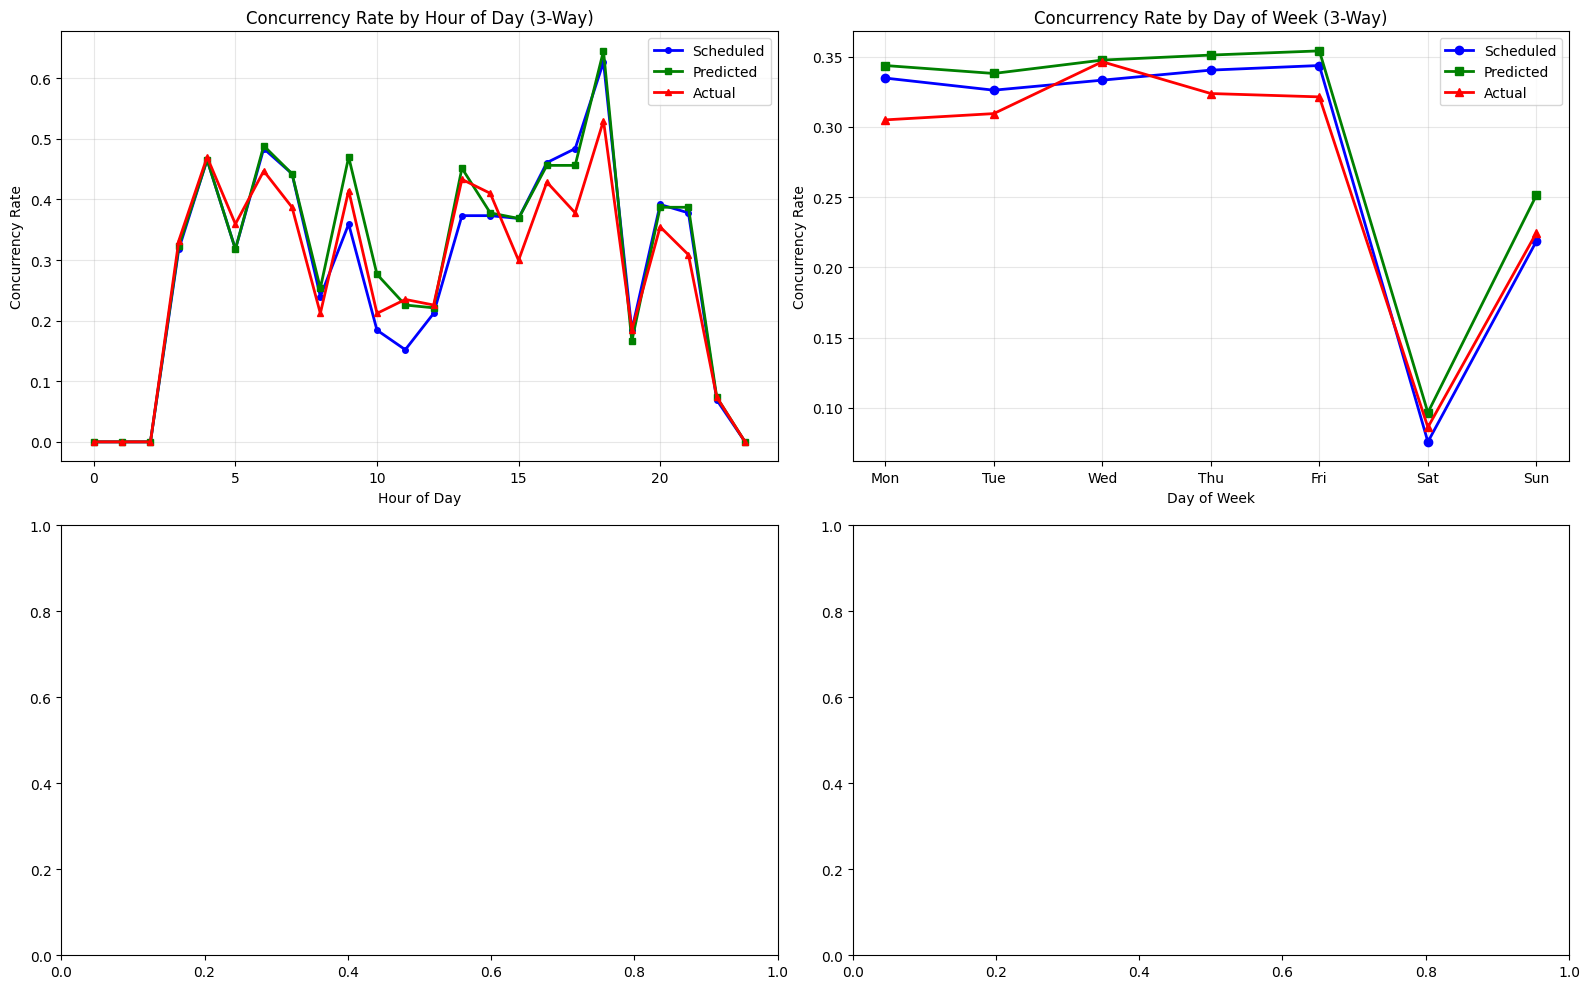

In [32]:
# Time-based pattern analysis (three-way)
print("\n⏰ TIME-BASED PATTERN ANALYSIS (Three-Way):")

# Hourly patterns for all three datasets
scheduled_hourly_3way = scheduled_df_oct.groupby("hour")["is_concurrency"].mean()
predicted_hourly_3way = predicted_df_oct.groupby("hour")["is_concurrency"].mean()
actual_hourly_3way = actual_df_oct.groupby("hour")["is_concurrency"].mean()

# Daily patterns (day of week) for all three datasets
scheduled_df_oct["day_of_week"] = pd.to_datetime(scheduled_df_oct["date"]).dt.dayofweek
predicted_df_oct["day_of_week"] = pd.to_datetime(predicted_df_oct["date"]).dt.dayofweek
actual_df_oct["day_of_week"] = pd.to_datetime(actual_df_oct["date"]).dt.dayofweek

scheduled_daily_3way = scheduled_df_oct.groupby("day_of_week")["is_concurrency"].mean()
predicted_daily_3way = predicted_df_oct.groupby("day_of_week")["is_concurrency"].mean()
actual_daily_3way = actual_df_oct.groupby("day_of_week")["is_concurrency"].mean()

# Plot time patterns (three-way)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Hourly pattern (three-way)
axes[0, 0].plot(
    scheduled_hourly_3way.index,
    scheduled_hourly_3way.values,
    "b-o",
    label="Scheduled",
    linewidth=2,
    markersize=4,
)
axes[0, 0].plot(
    predicted_hourly_3way.index,
    predicted_hourly_3way.values,
    "g-s",
    label="Predicted",
    linewidth=2,
    markersize=4,
)
axes[0, 0].plot(
    actual_hourly_3way.index,
    actual_hourly_3way.values,
    "r-^",
    label="Actual",
    linewidth=2,
    markersize=4,
)
axes[0, 0].set_xlabel("Hour of Day")
axes[0, 0].set_ylabel("Concurrency Rate")
axes[0, 0].set_title("Concurrency Rate by Hour of Day (3-Way)")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Daily pattern (three-way)
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
axes[0, 1].plot(
    scheduled_daily_3way.index,
    scheduled_daily_3way.values,
    "b-o",
    label="Scheduled",
    linewidth=2,
    markersize=6,
)
axes[0, 1].plot(
    predicted_daily_3way.index,
    predicted_daily_3way.values,
    "g-s",
    label="Predicted",
    linewidth=2,
    markersize=6,
)
axes[0, 1].plot(
    actual_daily_3way.index,
    actual_daily_3way.values,
    "r-^",
    label="Actual",
    linewidth=2,
    markersize=6,
)
axes[0, 1].set_xlabel("Day of Week")
axes[0, 1].set_ylabel("Concurrency Rate")
axes[0, 1].set_title("Concurrency Rate by Day of Week (3-Way)")
axes[0, 1].set_xticks(range(7))
axes[0, 1].set_xticklabels(day_names)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Correlation analysis
print(f"\n📊 CORRELATION ANALYSIS:")
print(
    f"• Scheduled vs Actual correlation: {scheduled_df_oct['is_concurrency'].corr(actual_df_oct['is_concurrency']):.3f}"
)
print(
    f"• Predicted vs Actual correlation: {predicted_df_oct['is_concurrency'].corr(actual_df_oct['is_concurrency']):.3f}"
)
print(
    f"• Scheduled vs Predicted correlation: {scheduled_df_oct['is_concurrency'].corr(predicted_df_oct['is_concurrency']):.3f}"
)

# Pattern differences analysis
hourly_pred_improvement = abs(predicted_hourly_3way - actual_hourly_3way).mean()
hourly_sched_improvement = abs(scheduled_hourly_3way - actual_hourly_3way).mean()

daily_pred_improvement = abs(predicted_daily_3way - actual_daily_3way).mean()
daily_sched_improvement = abs(scheduled_daily_3way - actual_daily_3way).mean()

print(f"\n🎯 PATTERN ACCURACY:")
print(f"• Hourly pattern - Predicted error: {hourly_pred_improvement:.3f}")
print(f"• Hourly pattern - Scheduled error: {hourly_sched_improvement:.3f}")
print(f"• Daily pattern - Predicted error: {daily_pred_improvement:.3f}")
print(f"• Daily pattern - Scheduled error: {daily_sched_improvement:.3f}")

plt.tight_layout()
plt.show()

In [33]:
# Detailed prediction accuracy analysis
print("\n🔍 DETAILED PREDICTION ACCURACY ANALYSIS:")
print("=" * 60)

# Binary classification metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

actual_binary = actual_df_oct["is_concurrency"].values
scheduled_binary = scheduled_df_oct["is_concurrency"].values
predicted_binary = predicted_df_oct["is_concurrency"].values

# Scheduled vs Actual metrics
sched_accuracy = accuracy_score(actual_binary, scheduled_binary)
sched_precision = precision_score(actual_binary, scheduled_binary, zero_division=0)
sched_recall = recall_score(actual_binary, scheduled_binary, zero_division=0)
sched_f1 = f1_score(actual_binary, scheduled_binary, zero_division=0)

# Predicted vs Actual metrics
pred_accuracy = accuracy_score(actual_binary, predicted_binary)
pred_precision = precision_score(actual_binary, predicted_binary, zero_division=0)
pred_recall = recall_score(actual_binary, predicted_binary, zero_division=0)
pred_f1 = f1_score(actual_binary, predicted_binary, zero_division=0)

print("📊 CLASSIFICATION METRICS COMPARISON:")
print(f"\nScheduled vs Actual:")
print(f"• Accuracy: {sched_accuracy:.3f}")
print(f"• Precision: {sched_precision:.3f}")
print(f"• Recall: {sched_recall:.3f}")
print(f"• F1-Score: {sched_f1:.3f}")

print(f"\nPredicted vs Actual:")
print(f"• Accuracy: {pred_accuracy:.3f}")
print(f"• Precision: {pred_precision:.3f}")
print(f"• Recall: {pred_recall:.3f}")
print(f"• F1-Score: {pred_f1:.3f}")

print(f"\n🎯 IMPROVEMENT METRICS:")
print(f"• Accuracy improvement: {pred_accuracy - sched_accuracy:+.3f}")
print(f"• Precision improvement: {pred_precision - sched_precision:+.3f}")
print(f"• Recall improvement: {pred_recall - sched_recall:+.3f}")
print(f"• F1-Score improvement: {pred_f1 - sched_f1:+.3f}")

# Confusion matrices
sched_cm = confusion_matrix(actual_binary, scheduled_binary)
pred_cm = confusion_matrix(actual_binary, predicted_binary)

print(f"\n📋 CONFUSION MATRICES:")
print(f"\nScheduled vs Actual:")
print(f"[[TN: {sched_cm[0,0]}, FP: {sched_cm[0,1]}]")
print(f" [FN: {sched_cm[1,0]}, TP: {sched_cm[1,1]}]]")

print(f"\nPredicted vs Actual:")
print(f"[[TN: {pred_cm[0,0]}, FP: {pred_cm[0,1]}]")
print(f" [FN: {pred_cm[1,0]}, TP: {pred_cm[1,1]}]]")

# Calculate relative improvement in each metric
improvements = {
    "Accuracy": (
        ((pred_accuracy - sched_accuracy) / sched_accuracy * 100)
        if sched_accuracy > 0
        else 0
    ),
    "Precision": (
        ((pred_precision - sched_precision) / sched_precision * 100)
        if sched_precision > 0
        else 0
    ),
    "Recall": (
        ((pred_recall - sched_recall) / sched_recall * 100) if sched_recall > 0 else 0
    ),
    "F1-Score": ((pred_f1 - sched_f1) / sched_f1 * 100) if sched_f1 > 0 else 0,
}

print(f"\n📈 RELATIVE IMPROVEMENTS (%):")
for metric, improvement in improvements.items():
    print(f"• {metric}: {improvement:+.1f}%")


🔍 DETAILED PREDICTION ACCURACY ANALYSIS:
📊 CLASSIFICATION METRICS COMPARISON:

Scheduled vs Actual:
• Accuracy: 0.927
• Precision: 0.859
• Recall: 0.884
• F1-Score: 0.871

Predicted vs Actual:
• Accuracy: 0.582
• Precision: 0.270
• Recall: 0.292
• F1-Score: 0.281

🎯 IMPROVEMENT METRICS:
• Accuracy improvement: -0.345
• Precision improvement: -0.589
• Recall improvement: -0.591
• F1-Score improvement: -0.591

📋 CONFUSION MATRICES:

Scheduled vs Actual:
[[TN: 3545, FP: 210]
 [FN: 169, TP: 1284]]

Predicted vs Actual:
[[TN: 2606, FP: 1149]
 [FN: 1028, TP: 425]]

📈 RELATIVE IMPROVEMENTS (%):
• Accuracy: -37.2%
• Precision: -68.6%
• Recall: -66.9%
• F1-Score: -67.8%


In [34]:
# Final comprehensive summary and recommendations
print("\n🎉 FINAL SUMMARY: ML PREDICTION PERFORMANCE")
print("=" * 80)

# Overall assessment
overall_scheduled_error = abs(scheduled_rate - actual_rate)
overall_predicted_error = abs(predicted_rate - actual_rate)
overall_improvement = (
    (overall_scheduled_error - overall_predicted_error) / overall_scheduled_error
) * 100

print(f"📊 OVERALL PERFORMANCE:")
print(f"• Scheduled concurrency rate: {scheduled_rate:.2%}")
print(f"• Predicted concurrency rate: {predicted_rate:.2%}")
print(f"• Actual concurrency rate: {actual_rate:.2%}")
print(f"• Schedule error: {overall_scheduled_error:.2%}")
print(f"• Prediction error: {overall_predicted_error:.2%}")
print(f"• Overall improvement: {overall_improvement:+.1f}%")

# Best and worst performing airports
best_airport = airport_comparison_3way["prediction_improvement"].idxmax()
worst_airport = airport_comparison_3way["prediction_improvement"].idxmin()
best_improvement = airport_comparison_3way.loc[best_airport, "prediction_improvement"]
worst_improvement = airport_comparison_3way.loc[worst_airport, "prediction_improvement"]

print(f"\n🏆 AIRPORT PERFORMANCE:")
print(
    f"• Best performing airport: {best_airport} ({best_improvement:+.1f}% improvement)"
)
print(
    f"• Worst performing airport: {worst_airport} ({worst_improvement:+.1f}% improvement)"
)

# Key insights
airports_improved = (airport_comparison_3way["prediction_improvement"] > 0).sum()
total_airports = len(airport_comparison_3way)

print(f"\n🔍 KEY INSIGHTS:")
print(f"• {airports_improved}/{total_airports} airports showed prediction improvements")
print(
    f"• Average prediction improvement: {airport_comparison_3way['prediction_improvement'].mean():.1f}%"
)
print(
    f"• Best classification metric improvement: {max(improvements.values()):.1f}% ({max(improvements, key=improvements.get)})"
)

# Recommendations
print(f"\n💡 RECOMMENDATIONS:")
if overall_improvement > 0:
    print(
        "✅ ML predictions are generally better than scheduled data for predicting actual concurrency"
    )
    print("✅ Consider using ML predictions for operational planning")
    if best_improvement > 20:
        print(
            f"✅ Focus on applying ML predictions especially at {best_airport} airport"
        )
else:
    print("⚠️ ML predictions are not consistently better than scheduled data")
    print("⚠️ Consider refining the ML model or using ensemble methods")

if airports_improved / total_airports > 0.5:
    print("✅ ML model shows improvement across majority of airports")
else:
    print("⚠️ ML model improvements are limited to specific airports")

print(
    f"\n✨ Analysis Complete! The ML model's performance has been thoroughly evaluated."
)

# Create a final summary table
summary_table = pd.DataFrame(
    {
        "Dataset": ["Scheduled", "Predicted", "Actual"],
        "Concurrency_Rate": [f"{rate:.2%}" for rate in rates_3way],
        "Total_Hours": [len(df) for df in dataframes_3way],
        "Concurrent_Hours": [df["is_concurrency"].sum() for df in dataframes_3way],
        "Avg_Flights_per_Hour": [
            f"{df['number_of_flights'].mean():.1f}" for df in dataframes_3way
        ],
    }
)

print(f"\n📋 SUMMARY TABLE:")
print(summary_table.to_string(index=False))


🎉 FINAL SUMMARY: ML PREDICTION PERFORMANCE
📊 OVERALL PERFORMANCE:
• Scheduled concurrency rate: 28.69%
• Predicted concurrency rate: 30.22%
• Actual concurrency rate: 27.90%
• Schedule error: 0.79%
• Prediction error: 2.32%
• Overall improvement: -195.1%

🏆 AIRPORT PERFORMANCE:
• Best performing airport: A (+83.0% improvement)
• Worst performing airport: C (-440.0% improvement)

🔍 KEY INSIGHTS:
• 1/7 airports showed prediction improvements
• Average prediction improvement: -126.9%
• Best classification metric improvement: -37.2% (Accuracy)

💡 RECOMMENDATIONS:
⚠️ ML predictions are not consistently better than scheduled data
⚠️ Consider refining the ML model or using ensemble methods
⚠️ ML model improvements are limited to specific airports

✨ Analysis Complete! The ML model's performance has been thoroughly evaluated.

📋 SUMMARY TABLE:
  Dataset Concurrency_Rate  Total_Hours  Concurrent_Hours Avg_Flights_per_Hour
Scheduled           28.69%         5208              1494               

In [35]:
def check_concurrency_sets(df1, df2):
    """Check if there are any concurrency events in the dataframe."""

    N_concurrency_diff = (df1["concurrency"] != df2["concurrency"]).sum()
    is_concurrency_diff = (df1["is_concurrency"] != df2["is_concurrency"]).sum()

    return N_concurrency_diff, is_concurrency_diff

In [36]:
def check_concurrency_inference_sets(c_df, i_df):
    """Check if there are any concurrency events in the dataframe."""

    N_flights_diff = (c_df["number_of_flights"] != i_df["number_of_flights"]).sum()
    is_concurrency_diff = (c_df["is_concurrency"] != i_df["is_concurrency"]).sum()

    return N_flights_diff, is_concurrency_diff

In [1]:
inference_df = pd.read_csv("../data/examples/inference_data_oct2025.csv")
inference_df = inference_df.rename(
    columns={
        "feat_sched_flights_cnt": "number_of_flights",
        "feat_sched_concurrence": "is_concurrency",
    }
)
concurrency_oct = pd.read_csv("../data/concurrency/scheduled_concurrency_oct_25.csv")

concurrency_oct = concurrency_oct.sort_values(
    ["airport_group", "date", "hour"]
).reset_index(drop=True)
inference_df = inference_df.sort_values(["airport_group", "date", "hour"]).reset_index(
    drop=True
)

print(len(concurrency_oct), len(inference_df))

N_flights_diff, is_concurrency_diff = check_concurrency_inference_sets(
    concurrency_oct, inference_df
)
print(f"N_flights_diff: {N_flights_diff}")
print(f"is_concurrency_diff: {is_concurrency_diff}")

print(
    concurrency_oct[
        concurrency_oct["is_concurrency"] != inference_df["is_concurrency"]
    ].describe()
)
print(
    inference_df[
        inference_df["is_concurrency"] != concurrency_oct["is_concurrency"]
    ].describe()
)

NameError: name 'pd' is not defined